BCHOICE - Simple Logit Model Example (Chocolate Candies) [Kuhfeld 2010]
10 subjects presented with 8 different chocolate candies choosing one
Dark vs Milk Chocolate, Soft vs Chewy Center, Nuts vs No Nuts

In [5]:
title 'Conjoint Analysis of Chocolate Candies';

data Chocs;
   input Subj Choice Dark Soft Nuts;
   datalines;
1 0 0 0 0
1 0 0 0 1
1 0 0 1 0
1 0 0 1 1
1 1 1 0 0
1 0 1 0 1
1 0 1 1 0
1 0 1 1 1
2 0 0 0 0
2 0 0 0 1
2 0 0 1 0
2 0 0 1 1
2 0 1 0 0
2 1 1 0 1
2 0 1 1 0
2 0 1 1 1
3 0 0 0 0
3 0 0 0 1
3 0 0 1 0
3 0 0 1 1
3 0 1 0 0
3 0 1 0 1
3 1 1 1 0
3 0 1 1 1
4 0 0 0 0
4 0 0 0 1
4 0 0 1 0
4 0 0 1 1
4 1 1 0 0
4 0 1 0 1
4 0 1 1 0
4 0 1 1 1
5 0 0 0 0
5 1 0 0 1
5 0 0 1 0
5 0 0 1 1
5 0 1 0 0
5 0 1 0 1
5 0 1 1 0
5 0 1 1 1
6 0 0 0 0
6 0 0 0 1
6 0 0 1 0
6 0 0 1 1
6 0 1 0 0
6 1 1 0 1
6 0 1 1 0
6 0 1 1 1
7 0 0 0 0
7 1 0 0 1
7 0 0 1 0
7 0 0 1 1
7 0 1 0 0
7 0 1 0 1
7 0 1 1 0
7 0 1 1 1
8 0 0 0 0
8 0 0 0 1
8 0 0 1 0
8 0 0 1 1
8 0 1 0 0
8 1 1 0 1
8 0 1 1 0
8 0 1 1 1
9 0 0 0 0
9 0 0 0 1
9 0 0 1 0
9 0 0 1 1
9 0 1 0 0
9 1 1 0 1
9 0 1 1 0
9 0 1 1 1
10 0 0 0 0
10 0 0 0 1
10 0 0 1 0
10 0 0 1 1
10 0 1 0 0
10 1 1 0 1
10 0 1 1 0
10 0 1 1 1
;

proc print data=Chocs (obs=16);
run;


Obs,Subj,Choice,Dark,Soft,Nuts
1,1,0,0,0,0
2,1,0,0,0,1
3,1,0,0,1,0
4,1,0,0,1,1
5,1,1,1,0,0
6,1,0,1,0,1
7,1,0,1,1,0
8,1,0,1,1,1
9,2,0,0,0,0
10,2,0,0,0,1



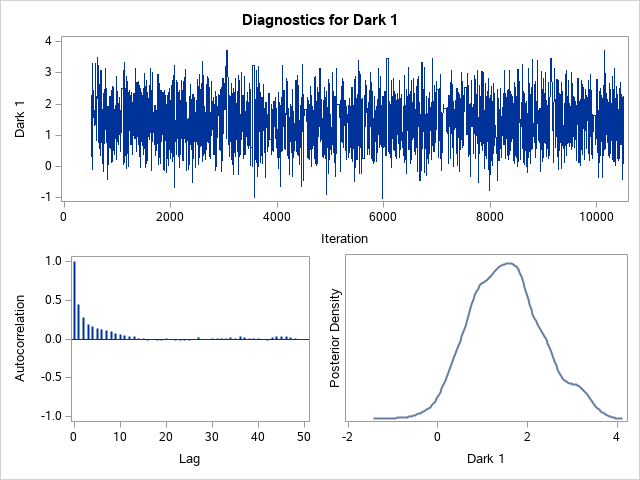
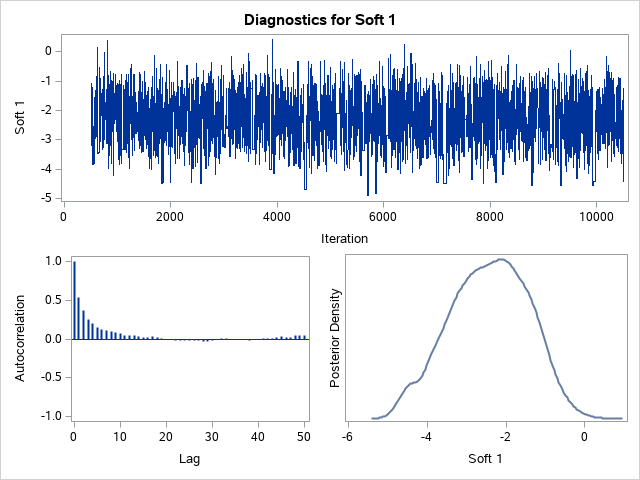
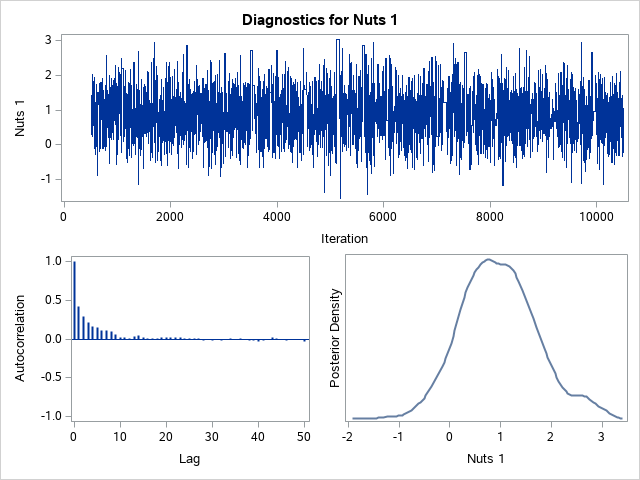

In [6]:
ods graphics on;
proc bchoice data=Chocs outpost=Bsamp nmc=10000 thin=2 diag=(AutoCorr
     ESS MCSE) seed=124;
   class Dark(ref='0') Soft(ref='0') Nuts(ref='0') Subj;
   model Choice = Dark Soft Nuts / choiceset=(Subj) cprior=normal(var=1000);
run;

BCHOICE - Logit Model with Random Effects Example (Trash Cans) [Kuhfeld 2010]
104 subjects presented with 10 choice tasks choosing one of each pairing
Touchless opening, Material (steel/plastic), Automatic bag replace, Price ($40/$80)

In [7]:
title 'Random Coefficient Model TrashCans';

data Trashcan;
   input ID Task Choice Index Touchless Steel AutoBag Price80 @@;
   datalines;
1 1 1 1 0 1 1 0 1 1 0 2 1 1 0 0 1 2 0 1 0 0 0 0 1 2 1 2 1 1 1 1 1 3 0 1
0 0 0 0 1 3 1 2 1 1 0 0 1 4 0 1 0 1 0 1 1 4 1 2 1 0 0 1 1 5 1 1 0 1 1 0
1 5 0 2 1 0 0 1 1 6 0 1 0 0 1 1 1 6 1 2 1 1 1 1 1 7 0 1 1 0 0 1 1 7 1 2
1 1 0 0 1 8 0 1 0 0 1 1 1 8 1 2 0 1 1 0 1 9 1 1 0 0 1 1 1 9 0 2 1 0 0 1
1 10 0 1 0 1 1 0 1 10 1 2 1 0 1 0 2 1 1 1 0 1 1 0 2 1 0 2 1 1 0 0 2 2 0
1 0 0 0 0 2 2 1 2 1 1 1 1 2 3 0 1 0 0 0 0 2 3 1 2 1 1 0 0 2 4 0 1 0 1 0
1 2 4 1 2 1 0 0 1 2 5 1 1 0 1 1 0 2 5 0 2 1 0 0 1 2 6 1 1 0 0 1 1 2 6 0
2 1 1 1 1 2 7 1 1 1 0 0 1 2 7 0 2 1 1 0 0 2 8 1 1 0 0 1 1 2 8 0 2 0 1 1
0 2 9 1 1 0 0 1 1 2 9 0 2 1 0 0 1 2 10 1 1 0 1 1 0 2 10 0 2 1 0 1 0 3 1
1 1 0 1 1 0 3 1 0 2 1 1 0 0 3 2 0 1 0 0 0 0 3 2 1 2 1 1 1 1 3 3 0 1 0 0
0 0 3 3 1 2 1 1 0 0 3 4 1 1 0 1 0 1 3 4 0 2 1 0 0 1 3 5 0 1 0 1 1 0 3 5
1 2 1 0 0 1 3 6 0 1 0 0 1 1 3 6 1 2 1 1 1 1 3 7 0 1 1 0 0 1 3 7 1 2 1 1
0 0 3 8 0 1 0 0 1 1 3 8 1 2 0 1 1 0 3 9 0 1 0 0 1 1 3 9 1 2 1 0 0 1 3 10
1 1 0 1 1 0 3 10 0 2 1 0 1 0 4 1 1 1 0 1 1 0 4 1 0 2 1 1 0 0 4 2 1 1 0 0
0 0 4 2 0 2 1 1 1 1 4 3 0 1 0 0 0 0 4 3 1 2 1 1 0 0 4 4 1 1 0 1 0 1 4 4
0 2 1 0 0 1 4 5 1 1 0 1 1 0 4 5 0 2 1 0 0 1 4 6 0 1 0 0 1 1 4 6 1 2 1 1
1 1 4 7 0 1 1 0 0 1 4 7 1 2 1 1 0 0 4 8 0 1 0 0 1 1 4 8 1 2 0 1 1 0 4 9
1 1 0 0 1 1 4 9 0 2 1 0 0 1 4 10 0 1 0 1 1 0 4 10 1 2 1 0 1 0 5 1 1 1 0
1 1 0 5 1 0 2 1 1 0 0 5 2 0 1 0 0 0 0 5 2 1 2 1 1 1 1 5 3 0 1 0 0 0 0 5
3 1 2 1 1 0 0 5 4 1 1 0 1 0 1 5 4 0 2 1 0 0 1 5 5 1 1 0 1 1 0 5 5 0 2 1
0 0 1 5 6 0 1 0 0 1 1 5 6 1 2 1 1 1 1 5 7 0 1 1 0 0 1 5 7 1 2 1 1 0 0 5
8 0 1 0 0 1 1 5 8 1 2 0 1 1 0 5 9 1 1 0 0 1 1 5 9 0 2 1 0 0 1 5 10 1 1 0
1 1 0 5 10 0 2 1 0 1 0 6 1 0 1 0 1 1 0 6 1 1 2 1 1 0 0 6 2 1 1 0 0 0 0 6
2 0 2 1 1 1 1 6 3 0 1 0 0 0 0 6 3 1 2 1 1 0 0 6 4 0 1 0 1 0 1 6 4 1 2 1
0 0 1 6 5 1 1 0 1 1 0 6 5 0 2 1 0 0 1 6 6 0 1 0 0 1 1 6 6 1 2 1 1 1 1 6
7 0 1 1 0 0 1 6 7 1 2 1 1 0 0 6 8 0 1 0 0 1 1 6 8 1 2 0 1 1 0 6 9 0 1 0
0 1 1 6 9 1 2 1 0 0 1 6 10 0 1 0 1 1 0 6 10 1 2 1 0 1 0 7 1 0 1 0 1 1 0
7 1 1 2 1 1 0 0 7 2 0 1 0 0 0 0 7 2 1 2 1 1 1 1 7 3 0 1 0 0 0 0 7 3 1 2
1 1 0 0 7 4 0 1 0 1 0 1 7 4 1 2 1 0 0 1 7 5 1 1 0 1 1 0 7 5 0 2 1 0 0 1
7 6 0 1 0 0 1 1 7 6 1 2 1 1 1 1 7 7 0 1 1 0 0 1 7 7 1 2 1 1 0 0 7 8 0 1
0 0 1 1 7 8 1 2 0 1 1 0 7 9 0 1 0 0 1 1 7 9 1 2 1 0 0 1 7 10 0 1 0 1 1 0
7 10 1 2 1 0 1 0 8 1 1 1 0 1 1 0 8 1 0 2 1 1 0 0 8 2 0 1 0 0 0 0 8 2 1 2
1 1 1 1 8 3 1 1 0 0 0 0 8 3 0 2 1 1 0 0 8 4 1 1 0 1 0 1 8 4 0 2 1 0 0 1
8 5 1 1 0 1 1 0 8 5 0 2 1 0 0 1 8 6 1 1 0 0 1 1 8 6 0 2 1 1 1 1 8 7 1 1
1 0 0 1 8 7 0 2 1 1 0 0 8 8 1 1 0 0 1 1 8 8 0 2 0 1 1 0 8 9 1 1 0 0 1 1
8 9 0 2 1 0 0 1 8 10 1 1 0 1 1 0 8 10 0 2 1 0 1 0 9 1 1 1 0 1 1 0 9 1 0
2 1 1 0 0 9 2 0 1 0 0 0 0 9 2 1 2 1 1 1 1 9 3 0 1 0 0 0 0 9 3 1 2 1 1 0
0 9 4 0 1 0 1 0 1 9 4 1 2 1 0 0 1 9 5 1 1 0 1 1 0 9 5 0 2 1 0 0 1 9 6 0
1 0 0 1 1 9 6 1 2 1 1 1 1 9 7 0 1 1 0 0 1 9 7 1 2 1 1 0 0 9 8 0 1 0 0 1
1 9 8 1 2 0 1 1 0 9 9 1 1 0 0 1 1 9 9 0 2 1 0 0 1 9 10 1 1 0 1 1 0 9 10
0 2 1 0 1 0 10 1 1 1 0 1 1 0 10 1 0 2 1 1 0 0 10 2 0 1 0 0 0 0 10 2 1 2
1 1 1 1 10 3 0 1 0 0 0 0 10 3 1 2 1 1 0 0 10 4 0 1 0 1 0 1 10 4 1 2 1 0
0 1 10 5 1 1 0 1 1 0 10 5 0 2 1 0 0 1 10 6 1 1 0 0 1 1 10 6 0 2 1 1 1 1
10 7 0 1 1 0 0 1 10 7 1 2 1 1 0 0 10 8 0 1 0 0 1 1 10 8 1 2 0 1 1 0 10 9
1 1 0 0 1 1 10 9 0 2 1 0 0 1 10 10 1 1 0 1 1 0 10 10 0 2 1 0 1 0 11 1 1
1 0 1 1 0 11 1 0 2 1 1 0 0 11 2 0 1 0 0 0 0 11 2 1 2 1 1 1 1 11 3 0 1 0
0 0 0 11 3 1 2 1 1 0 0 11 4 0 1 0 1 0 1 11 4 1 2 1 0 0 1 11 5 1 1 0 1 1
0 11 5 0 2 1 0 0 1 11 6 0 1 0 0 1 1 11 6 1 2 1 1 1 1 11 7 0 1 1 0 0 1 11
7 1 2 1 1 0 0 11 8 0 1 0 0 1 1 11 8 1 2 0 1 1 0 11 9 1 1 0 0 1 1 11 9 0
2 1 0 0 1 11 10 0 1 0 1 1 0 11 10 1 2 1 0 1 0 12 1 1 1 0 1 1 0 12 1 0 2
1 1 0 0 12 2 1 1 0 0 0 0 12 2 0 2 1 1 1 1 12 3 1 1 0 0 0 0 12 3 0 2 1 1
0 0 12 4 1 1 0 1 0 1 12 4 0 2 1 0 0 1 12 5 1 1 0 1 1 0 12 5 0 2 1 0 0 1
12 6 0 1 0 0 1 1 12 6 1 2 1 1 1 1 12 7 0 1 1 0 0 1 12 7 1 2 1 1 0 0 12 8
0 1 0 0 1 1 12 8 1 2 0 1 1 0 12 9 1 1 0 0 1 1 12 9 0 2 1 0 0 1 12 10 1 1
0 1 1 0 12 10 0 2 1 0 1 0 13 1 1 1 0 1 1 0 13 1 0 2 1 1 0 0 13 2 0 1 0 0
0 0 13 2 1 2 1 1 1 1 13 3 0 1 0 0 0 0 13 3 1 2 1 1 0 0 13 4 1 1 0 1 0 1
13 4 0 2 1 0 0 1 13 5 1 1 0 1 1 0 13 5 0 2 1 0 0 1 13 6 0 1 0 0 1 1 13 6
1 2 1 1 1 1 13 7 0 1 1 0 0 1 13 7 1 2 1 1 0 0 13 8 0 1 0 0 1 1 13 8 1 2
0 1 1 0 13 9 1 1 0 0 1 1 13 9 0 2 1 0 0 1 13 10 1 1 0 1 1 0 13 10 0 2 1
0 1 0 14 1 0 1 0 1 1 0 14 1 1 2 1 1 0 0 14 2 1 1 0 0 0 0 14 2 0 2 1 1 1
1 14 3 0 1 0 0 0 0 14 3 1 2 1 1 0 0 14 4 1 1 0 1 0 1 14 4 0 2 1 0 0 1 14
5 1 1 0 1 1 0 14 5 0 2 1 0 0 1 14 6 0 1 0 0 1 1 14 6 1 2 1 1 1 1 14 7 0
1 1 0 0 1 14 7 1 2 1 1 0 0 14 8 0 1 0 0 1 1 14 8 1 2 0 1 1 0 14 9 0 1 0
0 1 1 14 9 1 2 1 0 0 1 14 10 1 1 0 1 1 0 14 10 0 2 1 0 1 0 15 1 0 1 0 1
1 0 15 1 1 2 1 1 0 0 15 2 1 1 0 0 0 0 15 2 0 2 1 1 1 1 15 3 0 1 0 0 0 0
15 3 1 2 1 1 0 0 15 4 0 1 0 1 0 1 15 4 1 2 1 0 0 1 15 5 1 1 0 1 1 0 15 5
0 2 1 0 0 1 15 6 0 1 0 0 1 1 15 6 1 2 1 1 1 1 15 7 0 1 1 0 0 1 15 7 1 2
1 1 0 0 15 8 0 1 0 0 1 1 15 8 1 2 0 1 1 0 15 9 0 1 0 0 1 1 15 9 1 2 1 0
0 1 15 10 0 1 0 1 1 0 15 10 1 2 1 0 1 0 16 1 0 1 0 1 1 0 16 1 1 2 1 1 0
0 16 2 0 1 0 0 0 0 16 2 1 2 1 1 1 1 16 3 0 1 0 0 0 0 16 3 1 2 1 1 0 0 16
4 0 1 0 1 0 1 16 4 1 2 1 0 0 1 16 5 1 1 0 1 1 0 16 5 0 2 1 0 0 1 16 6 0
1 0 0 1 1 16 6 1 2 1 1 1 1 16 7 0 1 1 0 0 1 16 7 1 2 1 1 0 0 16 8 0 1 0
0 1 1 16 8 1 2 0 1 1 0 16 9 0 1 0 0 1 1 16 9 1 2 1 0 0 1 16 10 0 1 0 1 1
0 16 10 1 2 1 0 1 0 17 1 1 1 0 1 1 0 17 1 0 2 1 1 0 0 17 2 0 1 0 0 0 0
17 2 1 2 1 1 1 1 17 3 0 1 0 0 0 0 17 3 1 2 1 1 0 0 17 4 1 1 0 1 0 1 17 4
0 2 1 0 0 1 17 5 1 1 0 1 1 0 17 5 0 2 1 0 0 1 17 6 0 1 0 0 1 1 17 6 1 2
1 1 1 1 17 7 0 1 1 0 0 1 17 7 1 2 1 1 0 0 17 8 0 1 0 0 1 1 17 8 1 2 0 1
1 0 17 9 1 1 0 0 1 1 17 9 0 2 1 0 0 1 17 10 1 1 0 1 1 0 17 10 0 2 1 0 1
0 18 1 1 1 0 1 1 0 18 1 0 2 1 1 0 0 18 2 0 1 0 0 0 0 18 2 1 2 1 1 1 1 18
3 0 1 0 0 0 0 18 3 1 2 1 1 0 0 18 4 1 1 0 1 0 1 18 4 0 2 1 0 0 1 18 5 1
1 0 1 1 0 18 5 0 2 1 0 0 1 18 6 0 1 0 0 1 1 18 6 1 2 1 1 1 1 18 7 0 1 1
0 0 1 18 7 1 2 1 1 0 0 18 8 0 1 0 0 1 1 18 8 1 2 0 1 1 0 18 9 1 1 0 0 1
1 18 9 0 2 1 0 0 1 18 10 0 1 0 1 1 0 18 10 1 2 1 0 1 0 19 1 1 1 0 1 1 0
19 1 0 2 1 1 0 0 19 2 1 1 0 0 0 0 19 2 0 2 1 1 1 1 19 3 0 1 0 0 0 0 19 3
1 2 1 1 0 0 19 4 0 1 0 1 0 1 19 4 1 2 1 0 0 1 19 5 1 1 0 1 1 0 19 5 0 2
1 0 0 1 19 6 0 1 0 0 1 1 19 6 1 2 1 1 1 1 19 7 0 1 1 0 0 1 19 7 1 2 1 1
0 0 19 8 0 1 0 0 1 1 19 8 1 2 0 1 1 0 19 9 1 1 0 0 1 1 19 9 0 2 1 0 0 1
19 10 0 1 0 1 1 0 19 10 1 2 1 0 1 0 20 1 1 1 0 1 1 0 20 1 0 2 1 1 0 0 20
2 1 1 0 0 0 0 20 2 0 2 1 1 1 1 20 3 0 1 0 0 0 0 20 3 1 2 1 1 0 0 20 4 0
1 0 1 0 1 20 4 1 2 1 0 0 1 20 5 1 1 0 1 1 0 20 5 0 2 1 0 0 1 20 6 0 1 0
0 1 1 20 6 1 2 1 1 1 1 20 7 0 1 1 0 0 1 20 7 1 2 1 1 0 0 20 8 0 1 0 0 1
1 20 8 1 2 0 1 1 0 20 9 1 1 0 0 1 1 20 9 0 2 1 0 0 1 20 10 1 1 0 1 1 0
20 10 0 2 1 0 1 0 21 1 0 1 0 1 1 0 21 1 1 2 1 1 0 0 21 2 1 1 0 0 0 0 21
2 0 2 1 1 1 1 21 3 0 1 0 0 0 0 21 3 1 2 1 1 0 0 21 4 1 1 0 1 0 1 21 4 0
2 1 0 0 1 21 5 1 1 0 1 1 0 21 5 0 2 1 0 0 1 21 6 0 1 0 0 1 1 21 6 1 2 1
1 1 1 21 7 0 1 1 0 0 1 21 7 1 2 1 1 0 0 21 8 0 1 0 0 1 1 21 8 1 2 0 1 1
0 21 9 0 1 0 0 1 1 21 9 1 2 1 0 0 1 21 10 1 1 0 1 1 0 21 10 0 2 1 0 1 0
22 1 0 1 0 1 1 0 22 1 1 2 1 1 0 0 22 2 0 1 0 0 0 0 22 2 1 2 1 1 1 1 22 3
0 1 0 0 0 0 22 3 1 2 1 1 0 0 22 4 1 1 0 1 0 1 22 4 0 2 1 0 0 1 22 5 1 1
0 1 1 0 22 5 0 2 1 0 0 1 22 6 0 1 0 0 1 1 22 6 1 2 1 1 1 1 22 7 0 1 1 0
0 1 22 7 1 2 1 1 0 0 22 8 0 1 0 0 1 1 22 8 1 2 0 1 1 0 22 9 0 1 0 0 1 1
22 9 1 2 1 0 0 1 22 10 0 1 0 1 1 0 22 10 1 2 1 0 1 0 23 1 1 1 0 1 1 0 23
1 0 2 1 1 0 0 23 2 0 1 0 0 0 0 23 2 1 2 1 1 1 1 23 3 0 1 0 0 0 0 23 3 1
2 1 1 0 0 23 4 1 1 0 1 0 1 23 4 0 2 1 0 0 1 23 5 1 1 0 1 1 0 23 5 0 2 1
0 0 1 23 6 1 1 0 0 1 1 23 6 0 2 1 1 1 1 23 7 0 1 1 0 0 1 23 7 1 2 1 1 0
0 23 8 0 1 0 0 1 1 23 8 1 2 0 1 1 0 23 9 1 1 0 0 1 1 23 9 0 2 1 0 0 1 23
10 1 1 0 1 1 0 23 10 0 2 1 0 1 0 24 1 1 1 0 1 1 0 24 1 0 2 1 1 0 0 24 2
1 1 0 0 0 0 24 2 0 2 1 1 1 1 24 3 1 1 0 0 0 0 24 3 0 2 1 1 0 0 24 4 1 1
0 1 0 1 24 4 0 2 1 0 0 1 24 5 1 1 0 1 1 0 24 5 0 2 1 0 0 1 24 6 1 1 0 0
1 1 24 6 0 2 1 1 1 1 24 7 0 1 1 0 0 1 24 7 1 2 1 1 0 0 24 8 0 1 0 0 1 1
24 8 1 2 0 1 1 0 24 9 1 1 0 0 1 1 24 9 0 2 1 0 0 1 24 10 1 1 0 1 1 0 24
10 0 2 1 0 1 0 25 1 0 1 0 1 1 0 25 1 1 2 1 1 0 0 25 2 0 1 0 0 0 0 25 2 1
2 1 1 1 1 25 3 0 1 0 0 0 0 25 3 1 2 1 1 0 0 25 4 0 1 0 1 0 1 25 4 1 2 1
0 0 1 25 5 0 1 0 1 1 0 25 5 1 2 1 0 0 1 25 6 0 1 0 0 1 1 25 6 1 2 1 1 1
1 25 7 0 1 1 0 0 1 25 7 1 2 1 1 0 0 25 8 0 1 0 0 1 1 25 8 1 2 0 1 1 0 25
9 0 1 0 0 1 1 25 9 1 2 1 0 0 1 25 10 0 1 0 1 1 0 25 10 1 2 1 0 1 0 26 1
1 1 0 1 1 0 26 1 0 2 1 1 0 0 26 2 1 1 0 0 0 0 26 2 0 2 1 1 1 1 26 3 0 1
0 0 0 0 26 3 1 2 1 1 0 0 26 4 0 1 0 1 0 1 26 4 1 2 1 0 0 1 26 5 1 1 0 1
1 0 26 5 0 2 1 0 0 1 26 6 0 1 0 0 1 1 26 6 1 2 1 1 1 1 26 7 0 1 1 0 0 1
26 7 1 2 1 1 0 0 26 8 0 1 0 0 1 1 26 8 1 2 0 1 1 0 26 9 1 1 0 0 1 1 26 9
0 2 1 0 0 1 26 10 1 1 0 1 1 0 26 10 0 2 1 0 1 0 27 1 1 1 0 1 1 0 27 1 0
2 1 1 0 0 27 2 1 1 0 0 0 0 27 2 0 2 1 1 1 1 27 3 0 1 0 0 0 0 27 3 1 2 1
1 0 0 27 4 0 1 0 1 0 1 27 4 1 2 1 0 0 1 27 5 1 1 0 1 1 0 27 5 0 2 1 0 0
1 27 6 0 1 0 0 1 1 27 6 1 2 1 1 1 1 27 7 0 1 1 0 0 1 27 7 1 2 1 1 0 0 27
8 0 1 0 0 1 1 27 8 1 2 0 1 1 0 27 9 1 1 0 0 1 1 27 9 0 2 1 0 0 1 27 10 0
1 0 1 1 0 27 10 1 2 1 0 1 0 28 1 0 1 0 1 1 0 28 1 1 2 1 1 0 0 28 2 1 1 0
0 0 0 28 2 0 2 1 1 1 1 28 3 0 1 0 0 0 0 28 3 1 2 1 1 0 0 28 4 1 1 0 1 0
1 28 4 0 2 1 0 0 1 28 5 1 1 0 1 1 0 28 5 0 2 1 0 0 1 28 6 0 1 0 0 1 1 28
6 1 2 1 1 1 1 28 7 0 1 1 0 0 1 28 7 1 2 1 1 0 0 28 8 0 1 0 0 1 1 28 8 1
2 0 1 1 0 28 9 1 1 0 0 1 1 28 9 0 2 1 0 0 1 28 10 1 1 0 1 1 0 28 10 0 2
1 0 1 0 29 1 0 1 0 1 1 0 29 1 1 2 1 1 0 0 29 2 0 1 0 0 0 0 29 2 1 2 1 1
1 1 29 3 0 1 0 0 0 0 29 3 1 2 1 1 0 0 29 4 0 1 0 1 0 1 29 4 1 2 1 0 0 1
29 5 1 1 0 1 1 0 29 5 0 2 1 0 0 1 29 6 0 1 0 0 1 1 29 6 1 2 1 1 1 1 29 7
0 1 1 0 0 1 29 7 1 2 1 1 0 0 29 8 0 1 0 0 1 1 29 8 1 2 0 1 1 0 29 9 0 1
0 0 1 1 29 9 1 2 1 0 0 1 29 10 0 1 0 1 1 0 29 10 1 2 1 0 1 0 30 1 1 1 0
1 1 0 30 1 0 2 1 1 0 0 30 2 0 1 0 0 0 0 30 2 1 2 1 1 1 1 30 3 0 1 0 0 0
0 30 3 1 2 1 1 0 0 30 4 1 1 0 1 0 1 30 4 0 2 1 0 0 1 30 5 1 1 0 1 1 0 30
5 0 2 1 0 0 1 30 6 0 1 0 0 1 1 30 6 1 2 1 1 1 1 30 7 0 1 1 0 0 1 30 7 1
2 1 1 0 0 30 8 0 1 0 0 1 1 30 8 1 2 0 1 1 0 30 9 1 1 0 0 1 1 30 9 0 2 1
0 0 1 30 10 1 1 0 1 1 0 30 10 0 2 1 0 1 0 31 1 1 1 0 1 1 0 31 1 0 2 1 1
0 0 31 2 0 1 0 0 0 0 31 2 1 2 1 1 1 1 31 3 0 1 0 0 0 0 31 3 1 2 1 1 0 0
31 4 0 1 0 1 0 1 31 4 1 2 1 0 0 1 31 5 1 1 0 1 1 0 31 5 0 2 1 0 0 1 31 6
0 1 0 0 1 1 31 6 1 2 1 1 1 1 31 7 0 1 1 0 0 1 31 7 1 2 1 1 0 0 31 8 0 1
0 0 1 1 31 8 1 2 0 1 1 0 31 9 1 1 0 0 1 1 31 9 0 2 1 0 0 1 31 10 0 1 0 1
1 0 31 10 1 2 1 0 1 0 32 1 1 1 0 1 1 0 32 1 0 2 1 1 0 0 32 2 1 1 0 0 0 0
32 2 0 2 1 1 1 1 32 3 1 1 0 0 0 0 32 3 0 2 1 1 0 0 32 4 1 1 0 1 0 1 32 4
0 2 1 0 0 1 32 5 1 1 0 1 1 0 32 5 0 2 1 0 0 1 32 6 1 1 0 0 1 1 32 6 0 2
1 1 1 1 32 7 0 1 1 0 0 1 32 7 1 2 1 1 0 0 32 8 0 1 0 0 1 1 32 8 1 2 0 1
1 0 32 9 1 1 0 0 1 1 32 9 0 2 1 0 0 1 32 10 1 1 0 1 1 0 32 10 0 2 1 0 1
0 33 1 1 1 0 1 1 0 33 1 0 2 1 1 0 0 33 2 0 1 0 0 0 0 33 2 1 2 1 1 1 1 33
3 0 1 0 0 0 0 33 3 1 2 1 1 0 0 33 4 1 1 0 1 0 1 33 4 0 2 1 0 0 1 33 5 1
1 0 1 1 0 33 5 0 2 1 0 0 1 33 6 0 1 0 0 1 1 33 6 1 2 1 1 1 1 33 7 0 1 1
0 0 1 33 7 1 2 1 1 0 0 33 8 0 1 0 0 1 1 33 8 1 2 0 1 1 0 33 9 1 1 0 0 1
1 33 9 0 2 1 0 0 1 33 10 1 1 0 1 1 0 33 10 0 2 1 0 1 0 34 1 0 1 0 1 1 0
34 1 1 2 1 1 0 0 34 2 1 1 0 0 0 0 34 2 0 2 1 1 1 1 34 3 0 1 0 0 0 0 34 3
1 2 1 1 0 0 34 4 1 1 0 1 0 1 34 4 0 2 1 0 0 1 34 5 1 1 0 1 1 0 34 5 0 2
1 0 0 1 34 6 0 1 0 0 1 1 34 6 1 2 1 1 1 1 34 7 0 1 1 0 0 1 34 7 1 2 1 1
0 0 34 8 0 1 0 0 1 1 34 8 1 2 0 1 1 0 34 9 0 1 0 0 1 1 34 9 1 2 1 0 0 1
34 10 1 1 0 1 1 0 34 10 0 2 1 0 1 0 35 1 1 1 0 1 1 0 35 1 0 2 1 1 0 0 35
2 1 1 0 0 0 0 35 2 0 2 1 1 1 1 35 3 0 1 0 0 0 0 35 3 1 2 1 1 0 0 35 4 1
1 0 1 0 1 35 4 0 2 1 0 0 1 35 5 1 1 0 1 1 0 35 5 0 2 1 0 0 1 35 6 0 1 0
0 1 1 35 6 1 2 1 1 1 1 35 7 0 1 1 0 0 1 35 7 1 2 1 1 0 0 35 8 0 1 0 0 1
1 35 8 1 2 0 1 1 0 35 9 0 1 0 0 1 1 35 9 1 2 1 0 0 1 35 10 0 1 0 1 1 0
35 10 1 2 1 0 1 0 36 1 1 1 0 1 1 0 36 1 0 2 1 1 0 0 36 2 1 1 0 0 0 0 36
2 0 2 1 1 1 1 36 3 0 1 0 0 0 0 36 3 1 2 1 1 0 0 36 4 0 1 0 1 0 1 36 4 1
2 1 0 0 1 36 5 1 1 0 1 1 0 36 5 0 2 1 0 0 1 36 6 0 1 0 0 1 1 36 6 1 2 1
1 1 1 36 7 0 1 1 0 0 1 36 7 1 2 1 1 0 0 36 8 0 1 0 0 1 1 36 8 1 2 0 1 1
0 36 9 0 1 0 0 1 1 36 9 1 2 1 0 0 1 36 10 0 1 0 1 1 0 36 10 1 2 1 0 1 0
37 1 0 1 0 1 1 0 37 1 1 2 1 1 0 0 37 2 1 1 0 0 0 0 37 2 0 2 1 1 1 1 37 3
0 1 0 0 0 0 37 3 1 2 1 1 0 0 37 4 0 1 0 1 0 1 37 4 1 2 1 0 0 1 37 5 0 1
0 1 1 0 37 5 1 2 1 0 0 1 37 6 1 1 0 0 1 1 37 6 0 2 1 1 1 1 37 7 0 1 1 0
0 1 37 7 1 2 1 1 0 0 37 8 0 1 0 0 1 1 37 8 1 2 0 1 1 0 37 9 1 1 0 0 1 1
37 9 0 2 1 0 0 1 37 10 1 1 0 1 1 0 37 10 0 2 1 0 1 0 38 1 1 1 0 1 1 0 38
1 0 2 1 1 0 0 38 2 1 1 0 0 0 0 38 2 0 2 1 1 1 1 38 3 0 1 0 0 0 0 38 3 1
2 1 1 0 0 38 4 0 1 0 1 0 1 38 4 1 2 1 0 0 1 38 5 1 1 0 1 1 0 38 5 0 2 1
0 0 1 38 6 0 1 0 0 1 1 38 6 1 2 1 1 1 1 38 7 0 1 1 0 0 1 38 7 1 2 1 1 0
0 38 8 0 1 0 0 1 1 38 8 1 2 0 1 1 0 38 9 1 1 0 0 1 1 38 9 0 2 1 0 0 1 38
10 0 1 0 1 1 0 38 10 1 2 1 0 1 0 39 1 0 1 0 1 1 0 39 1 1 2 1 1 0 0 39 2
0 1 0 0 0 0 39 2 1 2 1 1 1 1 39 3 0 1 0 0 0 0 39 3 1 2 1 1 0 0 39 4 1 1
0 1 0 1 39 4 0 2 1 0 0 1 39 5 1 1 0 1 1 0 39 5 0 2 1 0 0 1 39 6 1 1 0 0
1 1 39 6 0 2 1 1 1 1 39 7 0 1 1 0 0 1 39 7 1 2 1 1 0 0 39 8 0 1 0 0 1 1
39 8 1 2 0 1 1 0 39 9 1 1 0 0 1 1 39 9 0 2 1 0 0 1 39 10 1 1 0 1 1 0 39
10 0 2 1 0 1 0 40 1 1 1 0 1 1 0 40 1 0 2 1 1 0 0 40 2 0 1 0 0 0 0 40 2 1
2 1 1 1 1 40 3 0 1 0 0 0 0 40 3 1 2 1 1 0 0 40 4 1 1 0 1 0 1 40 4 0 2 1
0 0 1 40 5 1 1 0 1 1 0 40 5 0 2 1 0 0 1 40 6 0 1 0 0 1 1 40 6 1 2 1 1 1
1 40 7 0 1 1 0 0 1 40 7 1 2 1 1 0 0 40 8 0 1 0 0 1 1 40 8 1 2 0 1 1 0 40
9 1 1 0 0 1 1 40 9 0 2 1 0 0 1 40 10 1 1 0 1 1 0 40 10 0 2 1 0 1 0 41 1
0 1 0 1 1 0 41 1 1 2 1 1 0 0 41 2 0 1 0 0 0 0 41 2 1 2 1 1 1 1 41 3 0 1
0 0 0 0 41 3 1 2 1 1 0 0 41 4 0 1 0 1 0 1 41 4 1 2 1 0 0 1 41 5 1 1 0 1
1 0 41 5 0 2 1 0 0 1 41 6 0 1 0 0 1 1 41 6 1 2 1 1 1 1 41 7 0 1 1 0 0 1
41 7 1 2 1 1 0 0 41 8 1 1 0 0 1 1 41 8 0 2 0 1 1 0 41 9 0 1 0 0 1 1 41 9
1 2 1 0 0 1 41 10 0 1 0 1 1 0 41 10 1 2 1 0 1 0 42 1 0 1 0 1 1 0 42 1 1
2 1 1 0 0 42 2 0 1 0 0 0 0 42 2 1 2 1 1 1 1 42 3 0 1 0 0 0 0 42 3 1 2 1
1 0 0 42 4 0 1 0 1 0 1 42 4 1 2 1 0 0 1 42 5 1 1 0 1 1 0 42 5 0 2 1 0 0
1 42 6 0 1 0 0 1 1 42 6 1 2 1 1 1 1 42 7 0 1 1 0 0 1 42 7 1 2 1 1 0 0 42
8 0 1 0 0 1 1 42 8 1 2 0 1 1 0 42 9 1 1 0 0 1 1 42 9 0 2 1 0 0 1 42 10 0
1 0 1 1 0 42 10 1 2 1 0 1 0 43 1 0 1 0 1 1 0 43 1 1 2 1 1 0 0 43 2 1 1 0
0 0 0 43 2 0 2 1 1 1 1 43 3 1 1 0 0 0 0 43 3 0 2 1 1 0 0 43 4 0 1 0 1 0
1 43 4 1 2 1 0 0 1 43 5 0 1 0 1 1 0 43 5 1 2 1 0 0 1 43 6 1 1 0 0 1 1 43
6 0 2 1 1 1 1 43 7 1 1 1 0 0 1 43 7 0 2 1 1 0 0 43 8 0 1 0 0 1 1 43 8 1
2 0 1 1 0 43 9 0 1 0 0 1 1 43 9 1 2 1 0 0 1 43 10 0 1 0 1 1 0 43 10 1 2
1 0 1 0 44 1 0 1 0 1 1 0 44 1 1 2 1 1 0 0 44 2 0 1 0 0 0 0 44 2 1 2 1 1
1 1 44 3 0 1 0 0 0 0 44 3 1 2 1 1 0 0 44 4 0 1 0 1 0 1 44 4 1 2 1 0 0 1
44 5 0 1 0 1 1 0 44 5 1 2 1 0 0 1 44 6 0 1 0 0 1 1 44 6 1 2 1 1 1 1 44 7
0 1 1 0 0 1 44 7 1 2 1 1 0 0 44 8 0 1 0 0 1 1 44 8 1 2 0 1 1 0 44 9 0 1
0 0 1 1 44 9 1 2 1 0 0 1 44 10 0 1 0 1 1 0 44 10 1 2 1 0 1 0 45 1 1 1 0
1 1 0 45 1 0 2 1 1 0 0 45 2 1 1 0 0 0 0 45 2 0 2 1 1 1 1 45 3 0 1 0 0 0
0 45 3 1 2 1 1 0 0 45 4 0 1 0 1 0 1 45 4 1 2 1 0 0 1 45 5 1 1 0 1 1 0 45
5 0 2 1 0 0 1 45 6 0 1 0 0 1 1 45 6 1 2 1 1 1 1 45 7 0 1 1 0 0 1 45 7 1
2 1 1 0 0 45 8 0 1 0 0 1 1 45 8 1 2 0 1 1 0 45 9 1 1 0 0 1 1 45 9 0 2 1
0 0 1 45 10 0 1 0 1 1 0 45 10 1 2 1 0 1 0 46 1 0 1 0 1 1 0 46 1 1 2 1 1
0 0 46 2 0 1 0 0 0 0 46 2 1 2 1 1 1 1 46 3 0 1 0 0 0 0 46 3 1 2 1 1 0 0
46 4 0 1 0 1 0 1 46 4 1 2 1 0 0 1 46 5 1 1 0 1 1 0 46 5 0 2 1 0 0 1 46 6
0 1 0 0 1 1 46 6 1 2 1 1 1 1 46 7 0 1 1 0 0 1 46 7 1 2 1 1 0 0 46 8 0 1
0 0 1 1 46 8 1 2 0 1 1 0 46 9 0 1 0 0 1 1 46 9 1 2 1 0 0 1 46 10 0 1 0 1
1 0 46 10 1 2 1 0 1 0 47 1 1 1 0 1 1 0 47 1 0 2 1 1 0 0 47 2 0 1 0 0 0 0
47 2 1 2 1 1 1 1 47 3 0 1 0 0 0 0 47 3 1 2 1 1 0 0 47 4 0 1 0 1 0 1 47 4
1 2 1 0 0 1 47 5 1 1 0 1 1 0 47 5 0 2 1 0 0 1 47 6 0 1 0 0 1 1 47 6 1 2
1 1 1 1 47 7 0 1 1 0 0 1 47 7 1 2 1 1 0 0 47 8 0 1 0 0 1 1 47 8 1 2 0 1
1 0 47 9 0 1 0 0 1 1 47 9 1 2 1 0 0 1 47 10 0 1 0 1 1 0 47 10 1 2 1 0 1
0 48 1 0 1 0 1 1 0 48 1 1 2 1 1 0 0 48 2 1 1 0 0 0 0 48 2 0 2 1 1 1 1 48
3 0 1 0 0 0 0 48 3 1 2 1 1 0 0 48 4 0 1 0 1 0 1 48 4 1 2 1 0 0 1 48 5 1
1 0 1 1 0 48 5 0 2 1 0 0 1 48 6 0 1 0 0 1 1 48 6 1 2 1 1 1 1 48 7 0 1 1
0 0 1 48 7 1 2 1 1 0 0 48 8 0 1 0 0 1 1 48 8 1 2 0 1 1 0 48 9 0 1 0 0 1
1 48 9 1 2 1 0 0 1 48 10 0 1 0 1 1 0 48 10 1 2 1 0 1 0 49 1 0 1 0 1 1 0
49 1 1 2 1 1 0 0 49 2 0 1 0 0 0 0 49 2 1 2 1 1 1 1 49 3 0 1 0 0 0 0 49 3
1 2 1 1 0 0 49 4 0 1 0 1 0 1 49 4 1 2 1 0 0 1 49 5 0 1 0 1 1 0 49 5 1 2
1 0 0 1 49 6 0 1 0 0 1 1 49 6 1 2 1 1 1 1 49 7 1 1 1 0 0 1 49 7 0 2 1 1
0 0 49 8 1 1 0 0 1 1 49 8 0 2 0 1 1 0 49 9 0 1 0 0 1 1 49 9 1 2 1 0 0 1
49 10 0 1 0 1 1 0 49 10 1 2 1 0 1 0 50 1 0 1 0 1 1 0 50 1 1 2 1 1 0 0 50
2 0 1 0 0 0 0 50 2 1 2 1 1 1 1 50 3 0 1 0 0 0 0 50 3 1 2 1 1 0 0 50 4 1
1 0 1 0 1 50 4 0 2 1 0 0 1 50 5 1 1 0 1 1 0 50 5 0 2 1 0 0 1 50 6 0 1 0
0 1 1 50 6 1 2 1 1 1 1 50 7 0 1 1 0 0 1 50 7 1 2 1 1 0 0 50 8 0 1 0 0 1
1 50 8 1 2 0 1 1 0 50 9 0 1 0 0 1 1 50 9 1 2 1 0 0 1 50 10 1 1 0 1 1 0
50 10 0 2 1 0 1 0 51 1 1 1 0 1 1 0 51 1 0 2 1 1 0 0 51 2 1 1 0 0 0 0 51
2 0 2 1 1 1 1 51 3 0 1 0 0 0 0 51 3 1 2 1 1 0 0 51 4 0 1 0 1 0 1 51 4 1
2 1 0 0 1 51 5 1 1 0 1 1 0 51 5 0 2 1 0 0 1 51 6 0 1 0 0 1 1 51 6 1 2 1
1 1 1 51 7 0 1 1 0 0 1 51 7 1 2 1 1 0 0 51 8 0 1 0 0 1 1 51 8 1 2 0 1 1
0 51 9 0 1 0 0 1 1 51 9 1 2 1 0 0 1 51 10 1 1 0 1 1 0 51 10 0 2 1 0 1 0
52 1 1 1 0 1 1 0 52 1 0 2 1 1 0 0 52 2 1 1 0 0 0 0 52 2 0 2 1 1 1 1 52 3
0 1 0 0 0 0 52 3 1 2 1 1 0 0 52 4 0 1 0 1 0 1 52 4 1 2 1 0 0 1 52 5 0 1
0 1 1 0 52 5 1 2 1 0 0 1 52 6 0 1 0 0 1 1 52 6 1 2 1 1 1 1 52 7 0 1 1 0
0 1 52 7 1 2 1 1 0 0 52 8 0 1 0 0 1 1 52 8 1 2 0 1 1 0 52 9 0 1 0 0 1 1
52 9 1 2 1 0 0 1 52 10 0 1 0 1 1 0 52 10 1 2 1 0 1 0 53 1 0 1 0 1 1 0 53
1 1 2 1 1 0 0 53 2 1 1 0 0 0 0 53 2 0 2 1 1 1 1 53 3 0 1 0 0 0 0 53 3 1
2 1 1 0 0 53 4 0 1 0 1 0 1 53 4 1 2 1 0 0 1 53 5 1 1 0 1 1 0 53 5 0 2 1
0 0 1 53 6 0 1 0 0 1 1 53 6 1 2 1 1 1 1 53 7 0 1 1 0 0 1 53 7 1 2 1 1 0
0 53 8 0 1 0 0 1 1 53 8 1 2 0 1 1 0 53 9 0 1 0 0 1 1 53 9 1 2 1 0 0 1 53
10 0 1 0 1 1 0 53 10 1 2 1 0 1 0 54 1 1 1 0 1 1 0 54 1 0 2 1 1 0 0 54 2
1 1 0 0 0 0 54 2 0 2 1 1 1 1 54 3 0 1 0 0 0 0 54 3 1 2 1 1 0 0 54 4 0 1
0 1 0 1 54 4 1 2 1 0 0 1 54 5 1 1 0 1 1 0 54 5 0 2 1 0 0 1 54 6 0 1 0 0
1 1 54 6 1 2 1 1 1 1 54 7 0 1 1 0 0 1 54 7 1 2 1 1 0 0 54 8 0 1 0 0 1 1
54 8 1 2 0 1 1 0 54 9 1 1 0 0 1 1 54 9 0 2 1 0 0 1 54 10 1 1 0 1 1 0 54
10 0 2 1 0 1 0 55 1 1 1 0 1 1 0 55 1 0 2 1 1 0 0 55 2 0 1 0 0 0 0 55 2 1
2 1 1 1 1 55 3 1 1 0 0 0 0 55 3 0 2 1 1 0 0 55 4 1 1 0 1 0 1 55 4 0 2 1
0 0 1 55 5 1 1 0 1 1 0 55 5 0 2 1 0 0 1 55 6 1 1 0 0 1 1 55 6 0 2 1 1 1
1 55 7 0 1 1 0 0 1 55 7 1 2 1 1 0 0 55 8 0 1 0 0 1 1 55 8 1 2 0 1 1 0 55
9 1 1 0 0 1 1 55 9 0 2 1 0 0 1 55 10 1 1 0 1 1 0 55 10 0 2 1 0 1 0 56 1
0 1 0 1 1 0 56 1 1 2 1 1 0 0 56 2 0 1 0 0 0 0 56 2 1 2 1 1 1 1 56 3 1 1
0 0 0 0 56 3 0 2 1 1 0 0 56 4 0 1 0 1 0 1 56 4 1 2 1 0 0 1 56 5 0 1 0 1
1 0 56 5 1 2 1 0 0 1 56 6 0 1 0 0 1 1 56 6 1 2 1 1 1 1 56 7 0 1 1 0 0 1
56 7 1 2 1 1 0 0 56 8 0 1 0 0 1 1 56 8 1 2 0 1 1 0 56 9 0 1 0 0 1 1 56 9
1 2 1 0 0 1 56 10 0 1 0 1 1 0 56 10 1 2 1 0 1 0 57 1 1 1 0 1 1 0 57 1 0
2 1 1 0 0 57 2 1 1 0 0 0 0 57 2 0 2 1 1 1 1 57 3 0 1 0 0 0 0 57 3 1 2 1
1 0 0 57 4 1 1 0 1 0 1 57 4 0 2 1 0 0 1 57 5 1 1 0 1 1 0 57 5 0 2 1 0 0
1 57 6 0 1 0 0 1 1 57 6 1 2 1 1 1 1 57 7 0 1 1 0 0 1 57 7 1 2 1 1 0 0 57
8 0 1 0 0 1 1 57 8 1 2 0 1 1 0 57 9 1 1 0 0 1 1 57 9 0 2 1 0 0 1 57 10 1
1 0 1 1 0 57 10 0 2 1 0 1 0 58 1 1 1 0 1 1 0 58 1 0 2 1 1 0 0 58 2 1 1 0
0 0 0 58 2 0 2 1 1 1 1 58 3 0 1 0 0 0 0 58 3 1 2 1 1 0 0 58 4 1 1 0 1 0
1 58 4 0 2 1 0 0 1 58 5 1 1 0 1 1 0 58 5 0 2 1 0 0 1 58 6 0 1 0 0 1 1 58
6 1 2 1 1 1 1 58 7 0 1 1 0 0 1 58 7 1 2 1 1 0 0 58 8 0 1 0 0 1 1 58 8 1
2 0 1 1 0 58 9 1 1 0 0 1 1 58 9 0 2 1 0 0 1 58 10 0 1 0 1 1 0 58 10 1 2
1 0 1 0 59 1 0 1 0 1 1 0 59 1 1 2 1 1 0 0 59 2 1 1 0 0 0 0 59 2 0 2 1 1
1 1 59 3 0 1 0 0 0 0 59 3 1 2 1 1 0 0 59 4 0 1 0 1 0 1 59 4 1 2 1 0 0 1
59 5 1 1 0 1 1 0 59 5 0 2 1 0 0 1 59 6 0 1 0 0 1 1 59 6 1 2 1 1 1 1 59 7
0 1 1 0 0 1 59 7 1 2 1 1 0 0 59 8 0 1 0 0 1 1 59 8 1 2 0 1 1 0 59 9 1 1
0 0 1 1 59 9 0 2 1 0 0 1 59 10 0 1 0 1 1 0 59 10 1 2 1 0 1 0 60 1 1 1 0
1 1 0 60 1 0 2 1 1 0 0 60 2 0 1 0 0 0 0 60 2 1 2 1 1 1 1 60 3 0 1 0 0 0
0 60 3 1 2 1 1 0 0 60 4 1 1 0 1 0 1 60 4 0 2 1 0 0 1 60 5 1 1 0 1 1 0 60
5 0 2 1 0 0 1 60 6 0 1 0 0 1 1 60 6 1 2 1 1 1 1 60 7 0 1 1 0 0 1 60 7 1
2 1 1 0 0 60 8 0 1 0 0 1 1 60 8 1 2 0 1 1 0 60 9 1 1 0 0 1 1 60 9 0 2 1
0 0 1 60 10 1 1 0 1 1 0 60 10 0 2 1 0 1 0 61 1 0 1 0 1 1 0 61 1 1 2 1 1
0 0 61 2 0 1 0 0 0 0 61 2 1 2 1 1 1 1 61 3 0 1 0 0 0 0 61 3 1 2 1 1 0 0
61 4 1 1 0 1 0 1 61 4 0 2 1 0 0 1 61 5 1 1 0 1 1 0 61 5 0 2 1 0 0 1 61 6
0 1 0 0 1 1 61 6 1 2 1 1 1 1 61 7 0 1 1 0 0 1 61 7 1 2 1 1 0 0 61 8 0 1
0 0 1 1 61 8 1 2 0 1 1 0 61 9 0 1 0 0 1 1 61 9 1 2 1 0 0 1 61 10 1 1 0 1
1 0 61 10 0 2 1 0 1 0 62 1 0 1 0 1 1 0 62 1 1 2 1 1 0 0 62 2 1 1 0 0 0 0
62 2 0 2 1 1 1 1 62 3 0 1 0 0 0 0 62 3 1 2 1 1 0 0 62 4 1 1 0 1 0 1 62 4
0 2 1 0 0 1 62 5 1 1 0 1 1 0 62 5 0 2 1 0 0 1 62 6 0 1 0 0 1 1 62 6 1 2
1 1 1 1 62 7 0 1 1 0 0 1 62 7 1 2 1 1 0 0 62 8 0 1 0 0 1 1 62 8 1 2 0 1
1 0 62 9 0 1 0 0 1 1 62 9 1 2 1 0 0 1 62 10 1 1 0 1 1 0 62 10 0 2 1 0 1
0 63 1 1 1 0 1 1 0 63 1 0 2 1 1 0 0 63 2 1 1 0 0 0 0 63 2 0 2 1 1 1 1 63
3 0 1 0 0 0 0 63 3 1 2 1 1 0 0 63 4 0 1 0 1 0 1 63 4 1 2 1 0 0 1 63 5 1
1 0 1 1 0 63 5 0 2 1 0 0 1 63 6 0 1 0 0 1 1 63 6 1 2 1 1 1 1 63 7 0 1 1
0 0 1 63 7 1 2 1 1 0 0 63 8 0 1 0 0 1 1 63 8 1 2 0 1 1 0 63 9 0 1 0 0 1
1 63 9 1 2 1 0 0 1 63 10 1 1 0 1 1 0 63 10 0 2 1 0 1 0 64 1 1 1 0 1 1 0
64 1 0 2 1 1 0 0 64 2 0 1 0 0 0 0 64 2 1 2 1 1 1 1 64 3 0 1 0 0 0 0 64 3
1 2 1 1 0 0 64 4 0 1 0 1 0 1 64 4 1 2 1 0 0 1 64 5 1 1 0 1 1 0 64 5 0 2
1 0 0 1 64 6 0 1 0 0 1 1 64 6 1 2 1 1 1 1 64 7 0 1 1 0 0 1 64 7 1 2 1 1
0 0 64 8 0 1 0 0 1 1 64 8 1 2 0 1 1 0 64 9 0 1 0 0 1 1 64 9 1 2 1 0 0 1
64 10 0 1 0 1 1 0 64 10 1 2 1 0 1 0 65 1 1 1 0 1 1 0 65 1 0 2 1 1 0 0 65
2 0 1 0 0 0 0 65 2 1 2 1 1 1 1 65 3 0 1 0 0 0 0 65 3 1 2 1 1 0 0 65 4 0
1 0 1 0 1 65 4 1 2 1 0 0 1 65 5 1 1 0 1 1 0 65 5 0 2 1 0 0 1 65 6 1 1 0
0 1 1 65 6 0 2 1 1 1 1 65 7 0 1 1 0 0 1 65 7 1 2 1 1 0 0 65 8 0 1 0 0 1
1 65 8 1 2 0 1 1 0 65 9 1 1 0 0 1 1 65 9 0 2 1 0 0 1 65 10 0 1 0 1 1 0
65 10 1 2 1 0 1 0 66 1 1 1 0 1 1 0 66 1 0 2 1 1 0 0 66 2 0 1 0 0 0 0 66
2 1 2 1 1 1 1 66 3 0 1 0 0 0 0 66 3 1 2 1 1 0 0 66 4 1 1 0 1 0 1 66 4 0
2 1 0 0 1 66 5 1 1 0 1 1 0 66 5 0 2 1 0 0 1 66 6 0 1 0 0 1 1 66 6 1 2 1
1 1 1 66 7 0 1 1 0 0 1 66 7 1 2 1 1 0 0 66 8 0 1 0 0 1 1 66 8 1 2 0 1 1
0 66 9 1 1 0 0 1 1 66 9 0 2 1 0 0 1 66 10 1 1 0 1 1 0 66 10 0 2 1 0 1 0
67 1 1 1 0 1 1 0 67 1 0 2 1 1 0 0 67 2 1 1 0 0 0 0 67 2 0 2 1 1 1 1 67 3
0 1 0 0 0 0 67 3 1 2 1 1 0 0 67 4 0 1 0 1 0 1 67 4 1 2 1 0 0 1 67 5 1 1
0 1 1 0 67 5 0 2 1 0 0 1 67 6 0 1 0 0 1 1 67 6 1 2 1 1 1 1 67 7 0 1 1 0
0 1 67 7 1 2 1 1 0 0 67 8 1 1 0 0 1 1 67 8 0 2 0 1 1 0 67 9 0 1 0 0 1 1
67 9 1 2 1 0 0 1 67 10 0 1 0 1 1 0 67 10 1 2 1 0 1 0 68 1 0 1 0 1 1 0 68
1 1 2 1 1 0 0 68 2 0 1 0 0 0 0 68 2 1 2 1 1 1 1 68 3 0 1 0 0 0 0 68 3 1
2 1 1 0 0 68 4 1 1 0 1 0 1 68 4 0 2 1 0 0 1 68 5 0 1 0 1 1 0 68 5 1 2 1
0 0 1 68 6 0 1 0 0 1 1 68 6 1 2 1 1 1 1 68 7 0 1 1 0 0 1 68 7 1 2 1 1 0
0 68 8 0 1 0 0 1 1 68 8 1 2 0 1 1 0 68 9 0 1 0 0 1 1 68 9 1 2 1 0 0 1 68
10 0 1 0 1 1 0 68 10 1 2 1 0 1 0 69 1 0 1 0 1 1 0 69 1 1 2 1 1 0 0 69 2
1 1 0 0 0 0 69 2 0 2 1 1 1 1 69 3 0 1 0 0 0 0 69 3 1 2 1 1 0 0 69 4 0 1
0 1 0 1 69 4 1 2 1 0 0 1 69 5 1 1 0 1 1 0 69 5 0 2 1 0 0 1 69 6 0 1 0 0
1 1 69 6 1 2 1 1 1 1 69 7 0 1 1 0 0 1 69 7 1 2 1 1 0 0 69 8 0 1 0 0 1 1
69 8 1 2 0 1 1 0 69 9 0 1 0 0 1 1 69 9 1 2 1 0 0 1 69 10 0 1 0 1 1 0 69
10 1 2 1 0 1 0 70 1 0 1 0 1 1 0 70 1 1 2 1 1 0 0 70 2 1 1 0 0 0 0 70 2 0
2 1 1 1 1 70 3 0 1 0 0 0 0 70 3 1 2 1 1 0 0 70 4 0 1 0 1 0 1 70 4 1 2 1
0 0 1 70 5 1 1 0 1 1 0 70 5 0 2 1 0 0 1 70 6 0 1 0 0 1 1 70 6 1 2 1 1 1
1 70 7 0 1 1 0 0 1 70 7 1 2 1 1 0 0 70 8 0 1 0 0 1 1 70 8 1 2 0 1 1 0 70
9 0 1 0 0 1 1 70 9 1 2 1 0 0 1 70 10 1 1 0 1 1 0 70 10 0 2 1 0 1 0 71 1
0 1 0 1 1 0 71 1 1 2 1 1 0 0 71 2 0 1 0 0 0 0 71 2 1 2 1 1 1 1 71 3 0 1
0 0 0 0 71 3 1 2 1 1 0 0 71 4 0 1 0 1 0 1 71 4 1 2 1 0 0 1 71 5 1 1 0 1
1 0 71 5 0 2 1 0 0 1 71 6 0 1 0 0 1 1 71 6 1 2 1 1 1 1 71 7 0 1 1 0 0 1
71 7 1 2 1 1 0 0 71 8 0 1 0 0 1 1 71 8 1 2 0 1 1 0 71 9 0 1 0 0 1 1 71 9
1 2 1 0 0 1 71 10 0 1 0 1 1 0 71 10 1 2 1 0 1 0 72 1 1 1 0 1 1 0 72 1 0
2 1 1 0 0 72 2 0 1 0 0 0 0 72 2 1 2 1 1 1 1 72 3 0 1 0 0 0 0 72 3 1 2 1
1 0 0 72 4 1 1 0 1 0 1 72 4 0 2 1 0 0 1 72 5 1 1 0 1 1 0 72 5 0 2 1 0 0
1 72 6 0 1 0 0 1 1 72 6 1 2 1 1 1 1 72 7 0 1 1 0 0 1 72 7 1 2 1 1 0 0 72
8 0 1 0 0 1 1 72 8 1 2 0 1 1 0 72 9 1 1 0 0 1 1 72 9 0 2 1 0 0 1 72 10 1
1 0 1 1 0 72 10 0 2 1 0 1 0 73 1 1 1 0 1 1 0 73 1 0 2 1 1 0 0 73 2 1 1 0
0 0 0 73 2 0 2 1 1 1 1 73 3 0 1 0 0 0 0 73 3 1 2 1 1 0 0 73 4 0 1 0 1 0
1 73 4 1 2 1 0 0 1 73 5 1 1 0 1 1 0 73 5 0 2 1 0 0 1 73 6 0 1 0 0 1 1 73
6 1 2 1 1 1 1 73 7 0 1 1 0 0 1 73 7 1 2 1 1 0 0 73 8 0 1 0 0 1 1 73 8 1
2 0 1 1 0 73 9 0 1 0 0 1 1 73 9 1 2 1 0 0 1 73 10 1 1 0 1 1 0 73 10 0 2
1 0 1 0 74 1 1 1 0 1 1 0 74 1 0 2 1 1 0 0 74 2 0 1 0 0 0 0 74 2 1 2 1 1
1 1 74 3 0 1 0 0 0 0 74 3 1 2 1 1 0 0 74 4 0 1 0 1 0 1 74 4 1 2 1 0 0 1
74 5 0 1 0 1 1 0 74 5 1 2 1 0 0 1 74 6 0 1 0 0 1 1 74 6 1 2 1 1 1 1 74 7
0 1 1 0 0 1 74 7 1 2 1 1 0 0 74 8 0 1 0 0 1 1 74 8 1 2 0 1 1 0 74 9 0 1
0 0 1 1 74 9 1 2 1 0 0 1 74 10 0 1 0 1 1 0 74 10 1 2 1 0 1 0 75 1 1 1 0
1 1 0 75 1 0 2 1 1 0 0 75 2 1 1 0 0 0 0 75 2 0 2 1 1 1 1 75 3 0 1 0 0 0
0 75 3 1 2 1 1 0 0 75 4 0 1 0 1 0 1 75 4 1 2 1 0 0 1 75 5 1 1 0 1 1 0 75
5 0 2 1 0 0 1 75 6 0 1 0 0 1 1 75 6 1 2 1 1 1 1 75 7 0 1 1 0 0 1 75 7 1
2 1 1 0 0 75 8 0 1 0 0 1 1 75 8 1 2 0 1 1 0 75 9 1 1 0 0 1 1 75 9 0 2 1
0 0 1 75 10 0 1 0 1 1 0 75 10 1 2 1 0 1 0 76 1 1 1 0 1 1 0 76 1 0 2 1 1
0 0 76 2 0 1 0 0 0 0 76 2 1 2 1 1 1 1 76 3 1 1 0 0 0 0 76 3 0 2 1 1 0 0
76 4 0 1 0 1 0 1 76 4 1 2 1 0 0 1 76 5 0 1 0 1 1 0 76 5 1 2 1 0 0 1 76 6
0 1 0 0 1 1 76 6 1 2 1 1 1 1 76 7 1 1 1 0 0 1 76 7 0 2 1 1 0 0 76 8 0 1
0 0 1 1 76 8 1 2 0 1 1 0 76 9 0 1 0 0 1 1 76 9 1 2 1 0 0 1 76 10 1 1 0 1
1 0 76 10 0 2 1 0 1 0 77 1 1 1 0 1 1 0 77 1 0 2 1 1 0 0 77 2 1 1 0 0 0 0
77 2 0 2 1 1 1 1 77 3 0 1 0 0 0 0 77 3 1 2 1 1 0 0 77 4 0 1 0 1 0 1 77 4
1 2 1 0 0 1 77 5 1 1 0 1 1 0 77 5 0 2 1 0 0 1 77 6 0 1 0 0 1 1 77 6 1 2
1 1 1 1 77 7 0 1 1 0 0 1 77 7 1 2 1 1 0 0 77 8 0 1 0 0 1 1 77 8 1 2 0 1
1 0 77 9 1 1 0 0 1 1 77 9 0 2 1 0 0 1 77 10 0 1 0 1 1 0 77 10 1 2 1 0 1
0 78 1 0 1 0 1 1 0 78 1 1 2 1 1 0 0 78 2 1 1 0 0 0 0 78 2 0 2 1 1 1 1 78
3 0 1 0 0 0 0 78 3 1 2 1 1 0 0 78 4 0 1 0 1 0 1 78 4 1 2 1 0 0 1 78 5 0
1 0 1 1 0 78 5 1 2 1 0 0 1 78 6 1 1 0 0 1 1 78 6 0 2 1 1 1 1 78 7 0 1 1
0 0 1 78 7 1 2 1 1 0 0 78 8 0 1 0 0 1 1 78 8 1 2 0 1 1 0 78 9 0 1 0 0 1
1 78 9 1 2 1 0 0 1 78 10 0 1 0 1 1 0 78 10 1 2 1 0 1 0 79 1 1 1 0 1 1 0
79 1 0 2 1 1 0 0 79 2 1 1 0 0 0 0 79 2 0 2 1 1 1 1 79 3 0 1 0 0 0 0 79 3
1 2 1 1 0 0 79 4 0 1 0 1 0 1 79 4 1 2 1 0 0 1 79 5 1 1 0 1 1 0 79 5 0 2
1 0 0 1 79 6 0 1 0 0 1 1 79 6 1 2 1 1 1 1 79 7 0 1 1 0 0 1 79 7 1 2 1 1
0 0 79 8 0 1 0 0 1 1 79 8 1 2 0 1 1 0 79 9 0 1 0 0 1 1 79 9 1 2 1 0 0 1
79 10 0 1 0 1 1 0 79 10 1 2 1 0 1 0 80 1 0 1 0 1 1 0 80 1 1 2 1 1 0 0 80
2 1 1 0 0 0 0 80 2 0 2 1 1 1 1 80 3 0 1 0 0 0 0 80 3 1 2 1 1 0 0 80 4 0
1 0 1 0 1 80 4 1 2 1 0 0 1 80 5 1 1 0 1 1 0 80 5 0 2 1 0 0 1 80 6 0 1 0
0 1 1 80 6 1 2 1 1 1 1 80 7 0 1 1 0 0 1 80 7 1 2 1 1 0 0 80 8 0 1 0 0 1
1 80 8 1 2 0 1 1 0 80 9 0 1 0 0 1 1 80 9 1 2 1 0 0 1 80 10 0 1 0 1 1 0
80 10 1 2 1 0 1 0 81 1 1 1 0 1 1 0 81 1 0 2 1 1 0 0 81 2 1 1 0 0 0 0 81
2 0 2 1 1 1 1 81 3 0 1 0 0 0 0 81 3 1 2 1 1 0 0 81 4 0 1 0 1 0 1 81 4 1
2 1 0 0 1 81 5 1 1 0 1 1 0 81 5 0 2 1 0 0 1 81 6 0 1 0 0 1 1 81 6 1 2 1
1 1 1 81 7 0 1 1 0 0 1 81 7 1 2 1 1 0 0 81 8 1 1 0 0 1 1 81 8 0 2 0 1 1
0 81 9 0 1 0 0 1 1 81 9 1 2 1 0 0 1 81 10 0 1 0 1 1 0 81 10 1 2 1 0 1 0
82 1 1 1 0 1 1 0 82 1 0 2 1 1 0 0 82 2 0 1 0 0 0 0 82 2 1 2 1 1 1 1 82 3
0 1 0 0 0 0 82 3 1 2 1 1 0 0 82 4 0 1 0 1 0 1 82 4 1 2 1 0 0 1 82 5 1 1
0 1 1 0 82 5 0 2 1 0 0 1 82 6 0 1 0 0 1 1 82 6 1 2 1 1 1 1 82 7 0 1 1 0
0 1 82 7 1 2 1 1 0 0 82 8 0 1 0 0 1 1 82 8 1 2 0 1 1 0 82 9 1 1 0 0 1 1
82 9 0 2 1 0 0 1 82 10 0 1 0 1 1 0 82 10 1 2 1 0 1 0 83 1 1 1 0 1 1 0 83
1 0 2 1 1 0 0 83 2 1 1 0 0 0 0 83 2 0 2 1 1 1 1 83 3 1 1 0 0 0 0 83 3 0
2 1 1 0 0 83 4 1 1 0 1 0 1 83 4 0 2 1 0 0 1 83 5 1 1 0 1 1 0 83 5 0 2 1
0 0 1 83 6 1 1 0 0 1 1 83 6 0 2 1 1 1 1 83 7 0 1 1 0 0 1 83 7 1 2 1 1 0
0 83 8 0 1 0 0 1 1 83 8 1 2 0 1 1 0 83 9 1 1 0 0 1 1 83 9 0 2 1 0 0 1 83
10 1 1 0 1 1 0 83 10 0 2 1 0 1 0 84 1 0 1 0 1 1 0 84 1 1 2 1 1 0 0 84 2
0 1 0 0 0 0 84 2 1 2 1 1 1 1 84 3 0 1 0 0 0 0 84 3 1 2 1 1 0 0 84 4 0 1
0 1 0 1 84 4 1 2 1 0 0 1 84 5 1 1 0 1 1 0 84 5 0 2 1 0 0 1 84 6 0 1 0 0
1 1 84 6 1 2 1 1 1 1 84 7 0 1 1 0 0 1 84 7 1 2 1 1 0 0 84 8 0 1 0 0 1 1
84 8 1 2 0 1 1 0 84 9 0 1 0 0 1 1 84 9 1 2 1 0 0 1 84 10 1 1 0 1 1 0 84
10 0 2 1 0 1 0 85 1 0 1 0 1 1 0 85 1 1 2 1 1 0 0 85 2 1 1 0 0 0 0 85 2 0
2 1 1 1 1 85 3 0 1 0 0 0 0 85 3 1 2 1 1 0 0 85 4 1 1 0 1 0 1 85 4 0 2 1
0 0 1 85 5 1 1 0 1 1 0 85 5 0 2 1 0 0 1 85 6 0 1 0 0 1 1 85 6 1 2 1 1 1
1 85 7 0 1 1 0 0 1 85 7 1 2 1 1 0 0 85 8 0 1 0 0 1 1 85 8 1 2 0 1 1 0 85
9 1 1 0 0 1 1 85 9 0 2 1 0 0 1 85 10 0 1 0 1 1 0 85 10 1 2 1 0 1 0 86 1
0 1 0 1 1 0 86 1 1 2 1 1 0 0 86 2 0 1 0 0 0 0 86 2 1 2 1 1 1 1 86 3 0 1
0 0 0 0 86 3 1 2 1 1 0 0 86 4 0 1 0 1 0 1 86 4 1 2 1 0 0 1 86 5 0 1 0 1
1 0 86 5 1 2 1 0 0 1 86 6 0 1 0 0 1 1 86 6 1 2 1 1 1 1 86 7 0 1 1 0 0 1
86 7 1 2 1 1 0 0 86 8 0 1 0 0 1 1 86 8 1 2 0 1 1 0 86 9 0 1 0 0 1 1 86 9
1 2 1 0 0 1 86 10 0 1 0 1 1 0 86 10 1 2 1 0 1 0 87 1 0 1 0 1 1 0 87 1 1
2 1 1 0 0 87 2 0 1 0 0 0 0 87 2 1 2 1 1 1 1 87 3 0 1 0 0 0 0 87 3 1 2 1
1 0 0 87 4 1 1 0 1 0 1 87 4 0 2 1 0 0 1 87 5 1 1 0 1 1 0 87 5 0 2 1 0 0
1 87 6 0 1 0 0 1 1 87 6 1 2 1 1 1 1 87 7 0 1 1 0 0 1 87 7 1 2 1 1 0 0 87
8 0 1 0 0 1 1 87 8 1 2 0 1 1 0 87 9 0 1 0 0 1 1 87 9 1 2 1 0 0 1 87 10 1
1 0 1 1 0 87 10 0 2 1 0 1 0 88 1 0 1 0 1 1 0 88 1 1 2 1 1 0 0 88 2 0 1 0
0 0 0 88 2 1 2 1 1 1 1 88 3 0 1 0 0 0 0 88 3 1 2 1 1 0 0 88 4 0 1 0 1 0
1 88 4 1 2 1 0 0 1 88 5 0 1 0 1 1 0 88 5 1 2 1 0 0 1 88 6 0 1 0 0 1 1 88
6 1 2 1 1 1 1 88 7 0 1 1 0 0 1 88 7 1 2 1 1 0 0 88 8 0 1 0 0 1 1 88 8 1
2 0 1 1 0 88 9 0 1 0 0 1 1 88 9 1 2 1 0 0 1 88 10 0 1 0 1 1 0 88 10 1 2
1 0 1 0 89 1 0 1 0 1 1 0 89 1 1 2 1 1 0 0 89 2 1 1 0 0 0 0 89 2 0 2 1 1
1 1 89 3 0 1 0 0 0 0 89 3 1 2 1 1 0 0 89 4 0 1 0 1 0 1 89 4 1 2 1 0 0 1
89 5 1 1 0 1 1 0 89 5 0 2 1 0 0 1 89 6 0 1 0 0 1 1 89 6 1 2 1 1 1 1 89 7
0 1 1 0 0 1 89 7 1 2 1 1 0 0 89 8 0 1 0 0 1 1 89 8 1 2 0 1 1 0 89 9 0 1
0 0 1 1 89 9 1 2 1 0 0 1 89 10 0 1 0 1 1 0 89 10 1 2 1 0 1 0 90 1 1 1 0
1 1 0 90 1 0 2 1 1 0 0 90 2 1 1 0 0 0 0 90 2 0 2 1 1 1 1 90 3 0 1 0 0 0
0 90 3 1 2 1 1 0 0 90 4 1 1 0 1 0 1 90 4 0 2 1 0 0 1 90 5 1 1 0 1 1 0 90
5 0 2 1 0 0 1 90 6 0 1 0 0 1 1 90 6 1 2 1 1 1 1 90 7 0 1 1 0 0 1 90 7 1
2 1 1 0 0 90 8 0 1 0 0 1 1 90 8 1 2 0 1 1 0 90 9 1 1 0 0 1 1 90 9 0 2 1
0 0 1 90 10 1 1 0 1 1 0 90 10 0 2 1 0 1 0 91 1 1 1 0 1 1 0 91 1 0 2 1 1
0 0 91 2 1 1 0 0 0 0 91 2 0 2 1 1 1 1 91 3 1 1 0 0 0 0 91 3 0 2 1 1 0 0
91 4 0 1 0 1 0 1 91 4 1 2 1 0 0 1 91 5 1 1 0 1 1 0 91 5 0 2 1 0 0 1 91 6
0 1 0 0 1 1 91 6 1 2 1 1 1 1 91 7 0 1 1 0 0 1 91 7 1 2 1 1 0 0 91 8 0 1
0 0 1 1 91 8 1 2 0 1 1 0 91 9 1 1 0 0 1 1 91 9 0 2 1 0 0 1 91 10 0 1 0 1
1 0 91 10 1 2 1 0 1 0 92 1 1 1 0 1 1 0 92 1 0 2 1 1 0 0 92 2 0 1 0 0 0 0
92 2 1 2 1 1 1 1 92 3 1 1 0 0 0 0 92 3 0 2 1 1 0 0 92 4 0 1 0 1 0 1 92 4
1 2 1 0 0 1 92 5 1 1 0 1 1 0 92 5 0 2 1 0 0 1 92 6 1 1 0 0 1 1 92 6 0 2
1 1 1 1 92 7 1 1 1 0 0 1 92 7 0 2 1 1 0 0 92 8 1 1 0 0 1 1 92 8 0 2 0 1
1 0 92 9 1 1 0 0 1 1 92 9 0 2 1 0 0 1 92 10 0 1 0 1 1 0 92 10 1 2 1 0 1
0 93 1 1 1 0 1 1 0 93 1 0 2 1 1 0 0 93 2 0 1 0 0 0 0 93 2 1 2 1 1 1 1 93
3 0 1 0 0 0 0 93 3 1 2 1 1 0 0 93 4 1 1 0 1 0 1 93 4 0 2 1 0 0 1 93 5 1
1 0 1 1 0 93 5 0 2 1 0 0 1 93 6 0 1 0 0 1 1 93 6 1 2 1 1 1 1 93 7 0 1 1
0 0 1 93 7 1 2 1 1 0 0 93 8 0 1 0 0 1 1 93 8 1 2 0 1 1 0 93 9 1 1 0 0 1
1 93 9 0 2 1 0 0 1 93 10 1 1 0 1 1 0 93 10 0 2 1 0 1 0 94 1 1 1 0 1 1 0
94 1 0 2 1 1 0 0 94 2 0 1 0 0 0 0 94 2 1 2 1 1 1 1 94 3 0 1 0 0 0 0 94 3
1 2 1 1 0 0 94 4 1 1 0 1 0 1 94 4 0 2 1 0 0 1 94 5 1 1 0 1 1 0 94 5 0 2
1 0 0 1 94 6 0 1 0 0 1 1 94 6 1 2 1 1 1 1 94 7 0 1 1 0 0 1 94 7 1 2 1 1
0 0 94 8 0 1 0 0 1 1 94 8 1 2 0 1 1 0 94 9 1 1 0 0 1 1 94 9 0 2 1 0 0 1
94 10 1 1 0 1 1 0 94 10 0 2 1 0 1 0 95 1 0 1 0 1 1 0 95 1 1 2 1 1 0 0 95
2 1 1 0 0 0 0 95 2 0 2 1 1 1 1 95 3 1 1 0 0 0 0 95 3 0 2 1 1 0 0 95 4 0
1 0 1 0 1 95 4 1 2 1 0 0 1 95 5 0 1 0 1 1 0 95 5 1 2 1 0 0 1 95 6 1 1 0
0 1 1 95 6 0 2 1 1 1 1 95 7 1 1 1 0 0 1 95 7 0 2 1 1 0 0 95 8 1 1 0 0 1
1 95 8 0 2 0 1 1 0 95 9 1 1 0 0 1 1 95 9 0 2 1 0 0 1 95 10 0 1 0 1 1 0
95 10 1 2 1 0 1 0 96 1 1 1 0 1 1 0 96 1 0 2 1 1 0 0 96 2 0 1 0 0 0 0 96
2 1 2 1 1 1 1 96 3 0 1 0 0 0 0 96 3 1 2 1 1 0 0 96 4 0 1 0 1 0 1 96 4 1
2 1 0 0 1 96 5 0 1 0 1 1 0 96 5 1 2 1 0 0 1 96 6 1 1 0 0 1 1 96 6 0 2 1
1 1 1 96 7 0 1 1 0 0 1 96 7 1 2 1 1 0 0 96 8 0 1 0 0 1 1 96 8 1 2 0 1 1
0 96 9 0 1 0 0 1 1 96 9 1 2 1 0 0 1 96 10 0 1 0 1 1 0 96 10 1 2 1 0 1 0
97 1 1 1 0 1 1 0 97 1 0 2 1 1 0 0 97 2 0 1 0 0 0 0 97 2 1 2 1 1 1 1 97 3
0 1 0 0 0 0 97 3 1 2 1 1 0 0 97 4 0 1 0 1 0 1 97 4 1 2 1 0 0 1 97 5 1 1
0 1 1 0 97 5 0 2 1 0 0 1 97 6 0 1 0 0 1 1 97 6 1 2 1 1 1 1 97 7 0 1 1 0
0 1 97 7 1 2 1 1 0 0 97 8 0 1 0 0 1 1 97 8 1 2 0 1 1 0 97 9 1 1 0 0 1 1
97 9 0 2 1 0 0 1 97 10 0 1 0 1 1 0 97 10 1 2 1 0 1 0 98 1 1 1 0 1 1 0 98
1 0 2 1 1 0 0 98 2 1 1 0 0 0 0 98 2 0 2 1 1 1 1 98 3 0 1 0 0 0 0 98 3 1
2 1 1 0 0 98 4 1 1 0 1 0 1 98 4 0 2 1 0 0 1 98 5 1 1 0 1 1 0 98 5 0 2 1
0 0 1 98 6 0 1 0 0 1 1 98 6 1 2 1 1 1 1 98 7 0 1 1 0 0 1 98 7 1 2 1 1 0
0 98 8 0 1 0 0 1 1 98 8 1 2 0 1 1 0 98 9 1 1 0 0 1 1 98 9 0 2 1 0 0 1 98
10 1 1 0 1 1 0 98 10 0 2 1 0 1 0 99 1 1 1 0 1 1 0 99 1 0 2 1 1 0 0 99 2
0 1 0 0 0 0 99 2 1 2 1 1 1 1 99 3 0 1 0 0 0 0 99 3 1 2 1 1 0 0 99 4 0 1
0 1 0 1 99 4 1 2 1 0 0 1 99 5 1 1 0 1 1 0 99 5 0 2 1 0 0 1 99 6 0 1 0 0
1 1 99 6 1 2 1 1 1 1 99 7 0 1 1 0 0 1 99 7 1 2 1 1 0 0 99 8 0 1 0 0 1 1
99 8 1 2 0 1 1 0 99 9 1 1 0 0 1 1 99 9 0 2 1 0 0 1 99 10 0 1 0 1 1 0 99
10 1 2 1 0 1 0 100 1 0 1 0 1 1 0 100 1 1 2 1 1 0 0 100 2 0 1 0 0 0 0 100
2 1 2 1 1 1 1 100 3 0 1 0 0 0 0 100 3 1 2 1 1 0 0 100 4 0 1 0 1 0 1 100
4 1 2 1 0 0 1 100 5 1 1 0 1 1 0 100 5 0 2 1 0 0 1 100 6 0 1 0 0 1 1 100
6 1 2 1 1 1 1 100 7 0 1 1 0 0 1 100 7 1 2 1 1 0 0 100 8 0 1 0 0 1 1 100
8 1 2 0 1 1 0 100 9 0 1 0 0 1 1 100 9 1 2 1 0 0 1 100 10 1 1 0 1 1 0 100
10 0 2 1 0 1 0 101 1 1 1 0 1 1 0 101 1 0 2 1 1 0 0 101 2 1 1 0 0 0 0 101
2 0 2 1 1 1 1 101 3 1 1 0 0 0 0 101 3 0 2 1 1 0 0 101 4 1 1 0 1 0 1 101
4 0 2 1 0 0 1 101 5 1 1 0 1 1 0 101 5 0 2 1 0 0 1 101 6 1 1 0 0 1 1 101
6 0 2 1 1 1 1 101 7 0 1 1 0 0 1 101 7 1 2 1 1 0 0 101 8 0 1 0 0 1 1 101
8 1 2 0 1 1 0 101 9 1 1 0 0 1 1 101 9 0 2 1 0 0 1 101 10 0 1 0 1 1 0 101
10 1 2 1 0 1 0 102 1 1 1 0 1 1 0 102 1 0 2 1 1 0 0 102 2 1 1 0 0 0 0 102
2 0 2 1 1 1 1 102 3 0 1 0 0 0 0 102 3 1 2 1 1 0 0 102 4 1 1 0 1 0 1 102
4 0 2 1 0 0 1 102 5 1 1 0 1 1 0 102 5 0 2 1 0 0 1 102 6 0 1 0 0 1 1 102
6 1 2 1 1 1 1 102 7 0 1 1 0 0 1 102 7 1 2 1 1 0 0 102 8 0 1 0 0 1 1 102
8 1 2 0 1 1 0 102 9 1 1 0 0 1 1 102 9 0 2 1 0 0 1 102 10 1 1 0 1 1 0 102
10 0 2 1 0 1 0 103 1 1 1 0 1 1 0 103 1 0 2 1 1 0 0 103 2 0 1 0 0 0 0 103
2 1 2 1 1 1 1 103 3 0 1 0 0 0 0 103 3 1 2 1 1 0 0 103 4 0 1 0 1 0 1 103
4 1 2 1 0 0 1 103 5 1 1 0 1 1 0 103 5 0 2 1 0 0 1 103 6 0 1 0 0 1 1 103
6 1 2 1 1 1 1 103 7 0 1 1 0 0 1 103 7 1 2 1 1 0 0 103 8 0 1 0 0 1 1 103
8 1 2 0 1 1 0 103 9 1 1 0 0 1 1 103 9 0 2 1 0 0 1 103 10 0 1 0 1 1 0 103
10 1 2 1 0 1 0 104 1 1 1 0 1 1 0 104 1 0 2 1 1 0 0 104 2 0 1 0 0 0 0 104
2 1 2 1 1 1 1 104 3 0 1 0 0 0 0 104 3 1 2 1 1 0 0 104 4 0 1 0 1 0 1 104
4 1 2 1 0 0 1 104 5 1 1 0 1 1 0 104 5 0 2 1 0 0 1 104 6 0 1 0 0 1 1 104
6 1 2 1 1 1 1 104 7 0 1 1 0 0 1 104 7 1 2 1 1 0 0 104 8 0 1 0 0 1 1 104
8 1 2 0 1 1 0 104 9 0 1 0 0 1 1 104 9 1 2 1 0 0 1 104 10 0 1 0 1 1 0 104
10 1 2 1 0 1 0
;

proc print data=Trashcan (obs=8);
run;


Obs,ID,Task,Choice,Index,Touchless,Steel,AutoBag,Price80
1,1,1,1,1,0,1,1,0
2,1,1,0,2,1,1,0,0
3,1,2,0,1,0,0,0,0
4,1,2,1,2,1,1,1,1
5,1,3,0,1,0,0,0,0
6,1,3,1,2,1,1,0,0
7,1,4,0,1,0,1,0,1
8,1,4,1,2,1,0,0,1



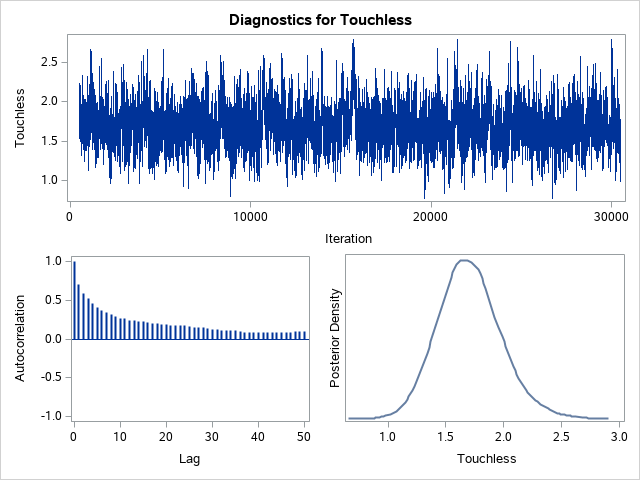
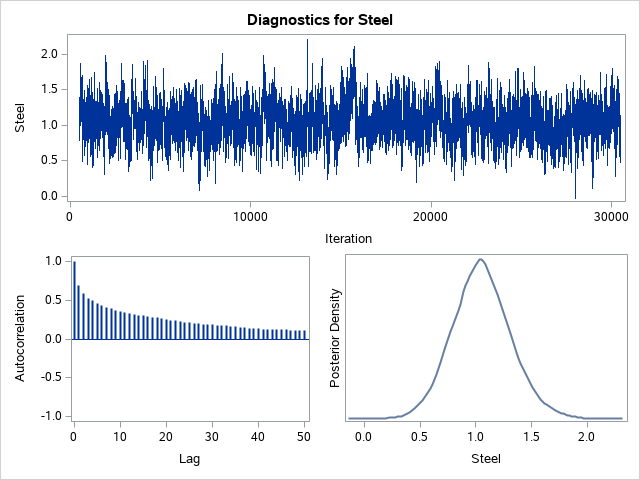
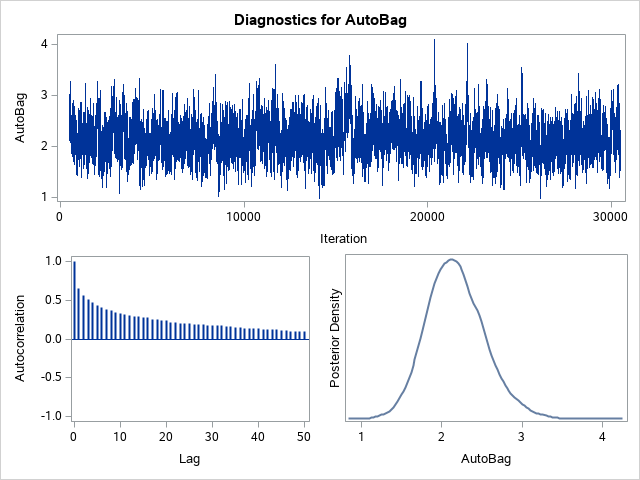
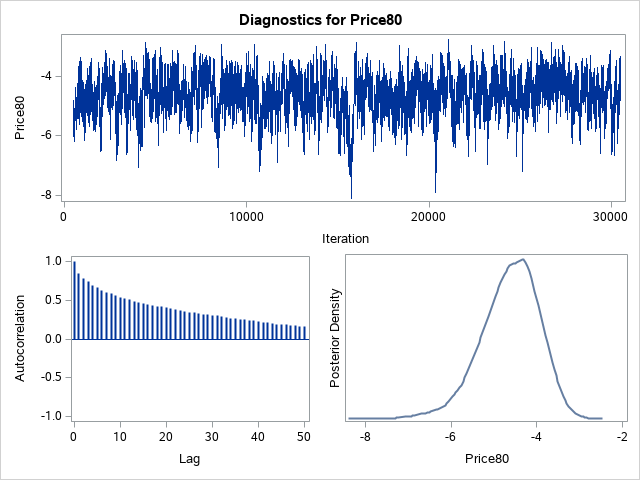
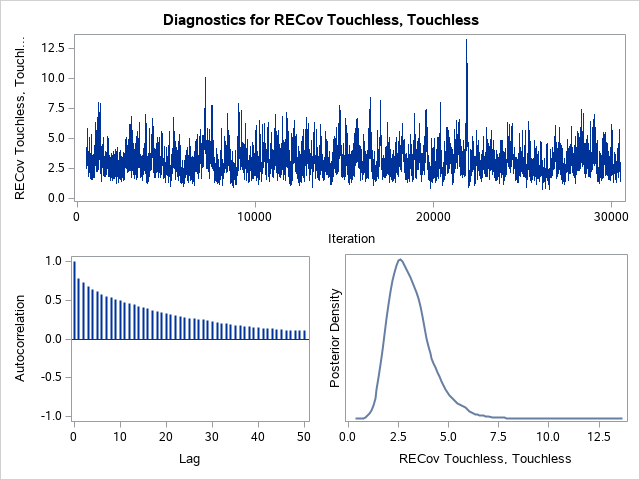
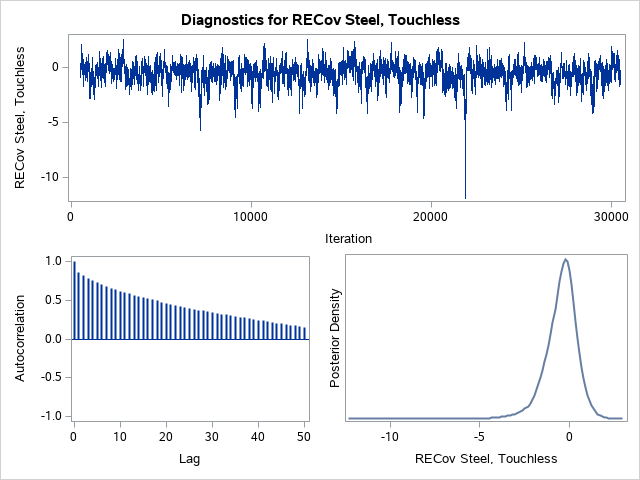
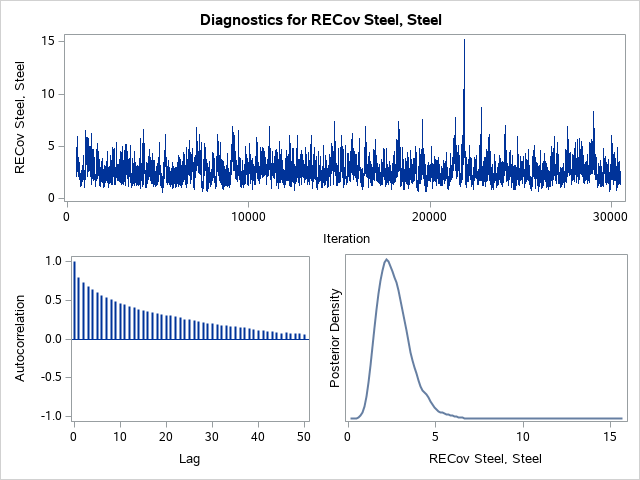
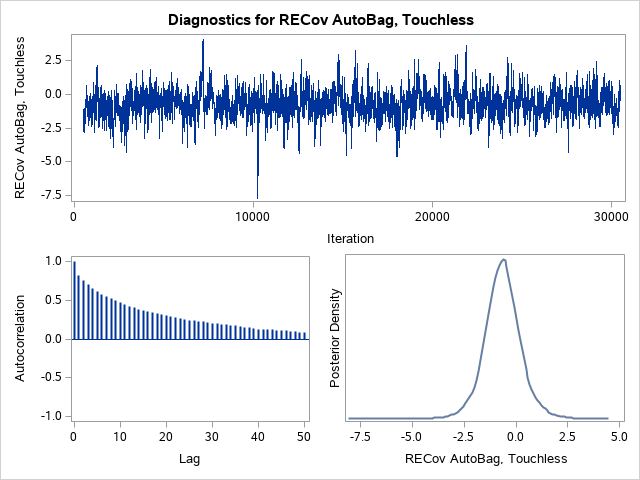
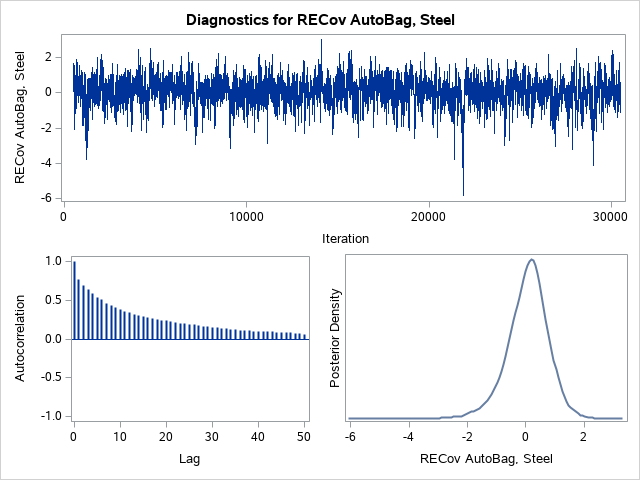
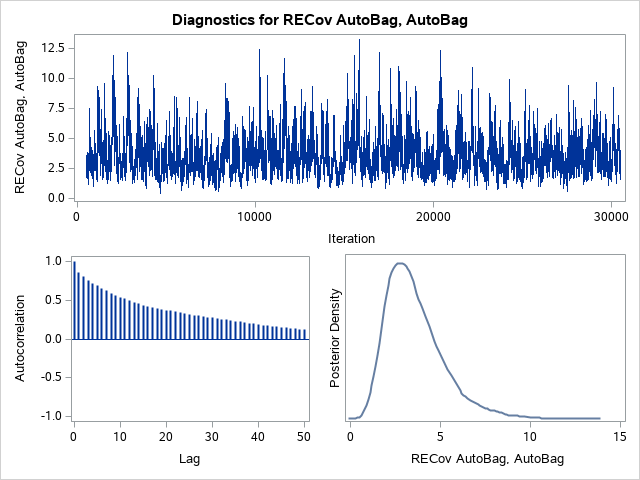
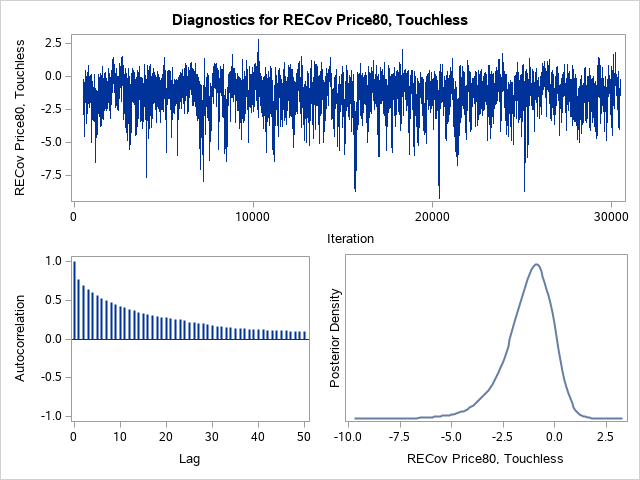
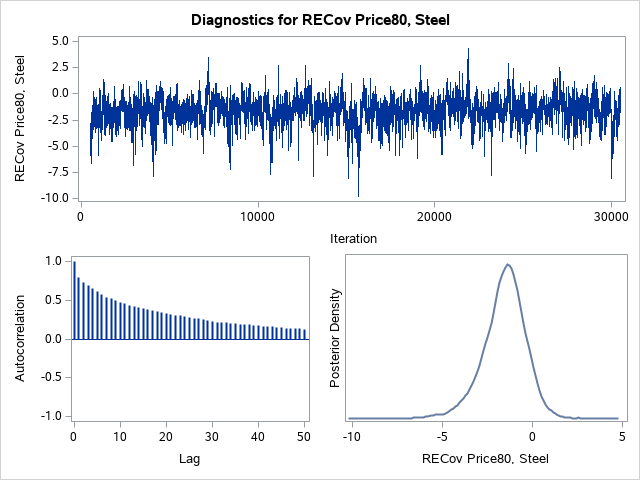
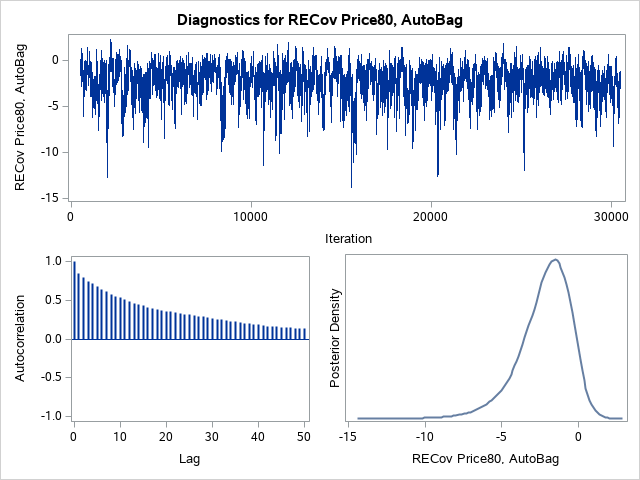
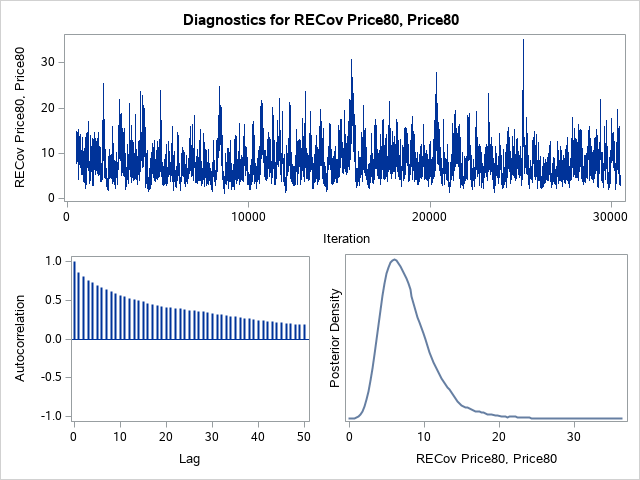
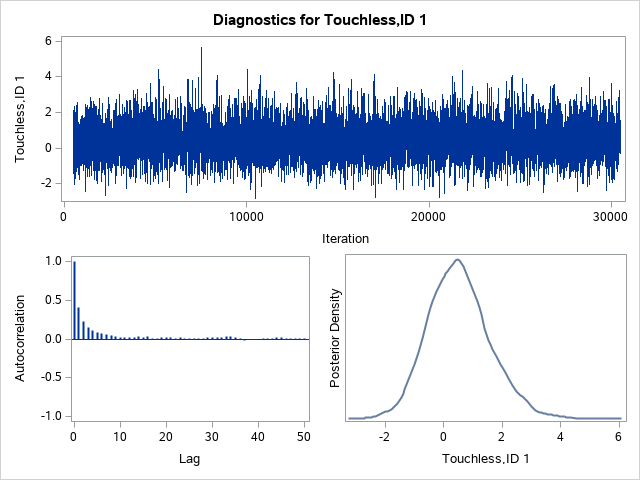
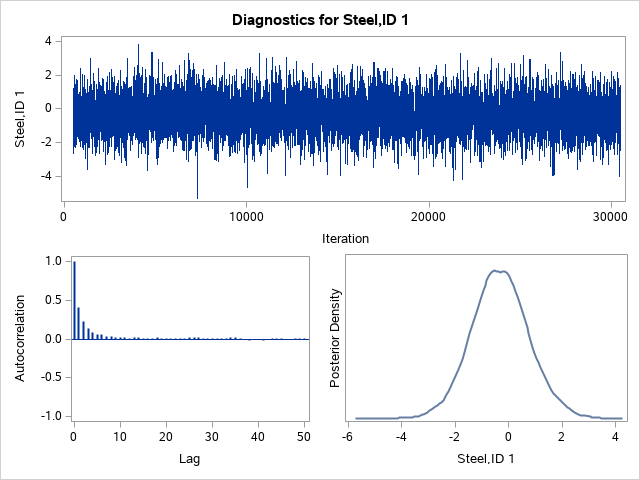
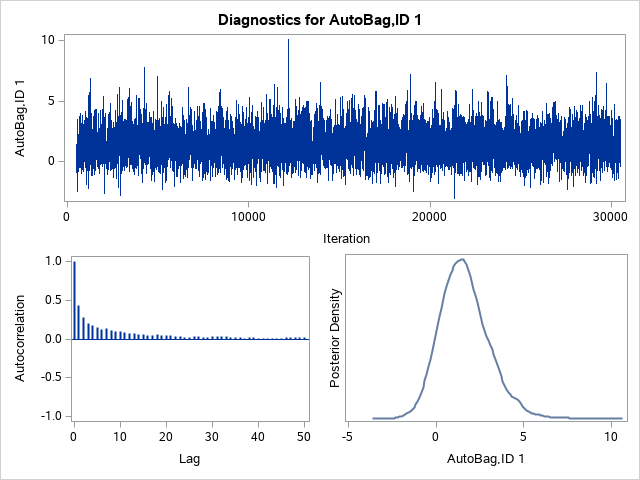
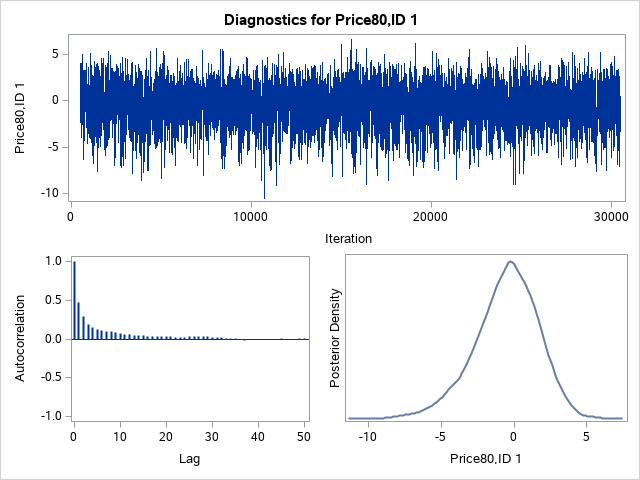
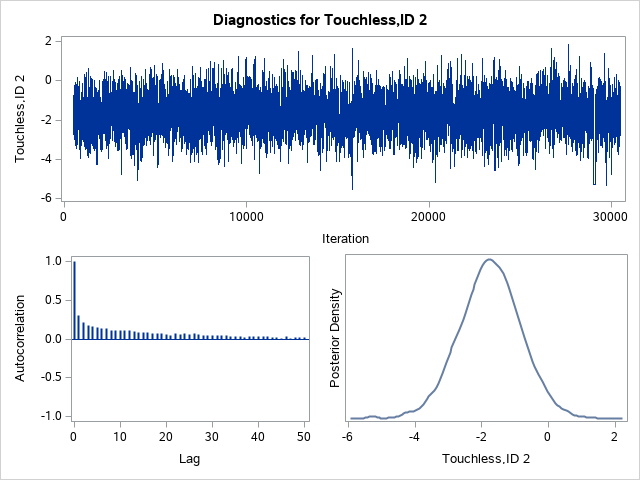
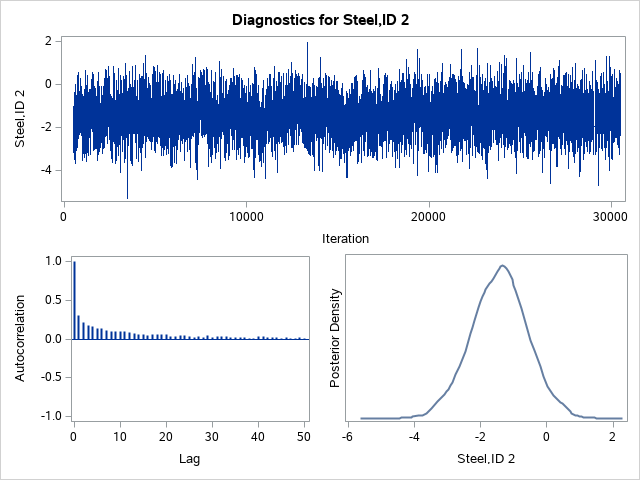
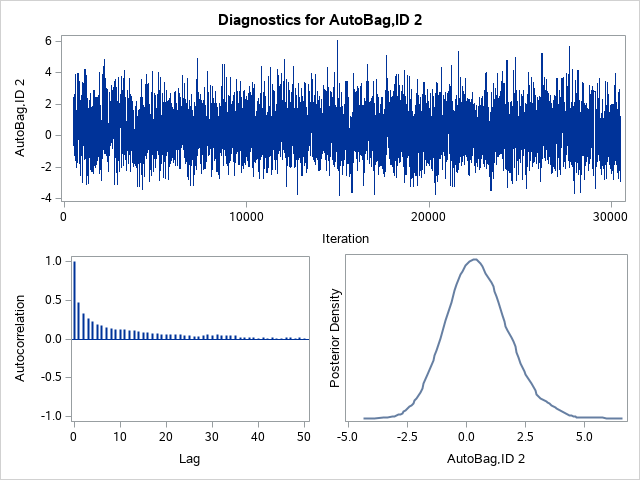
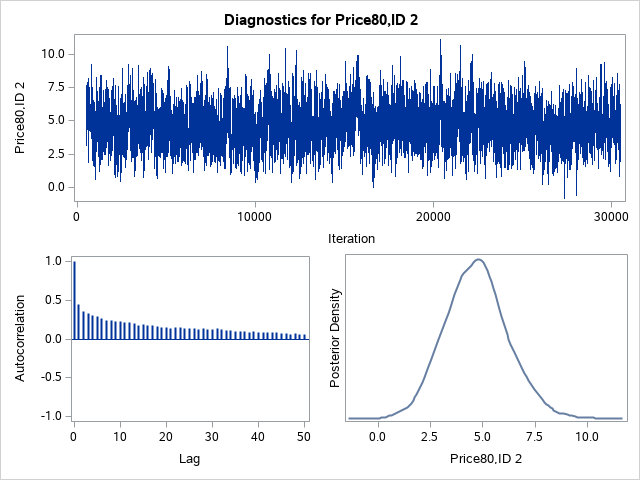
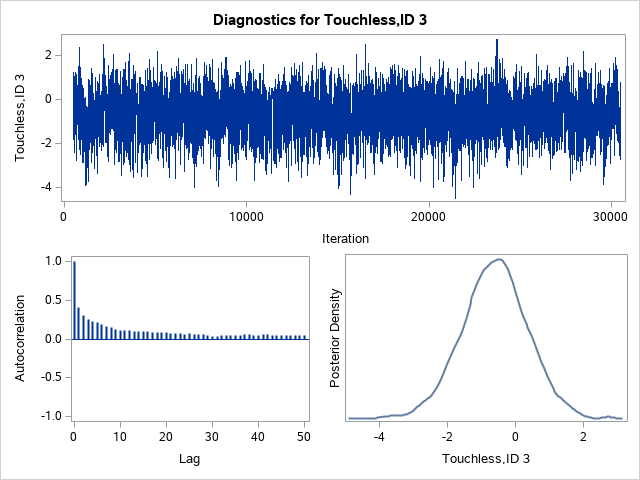
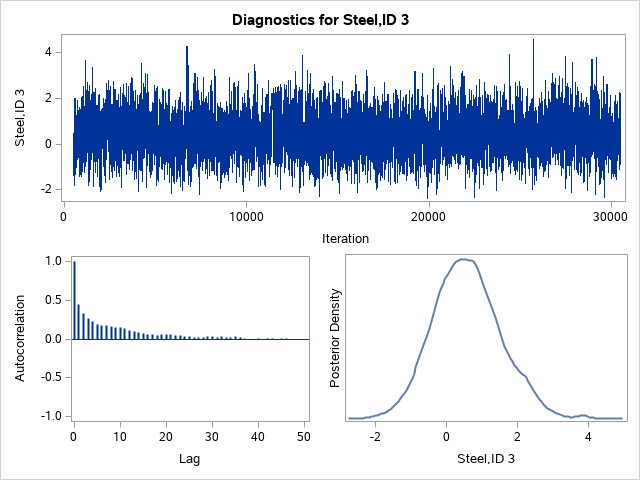
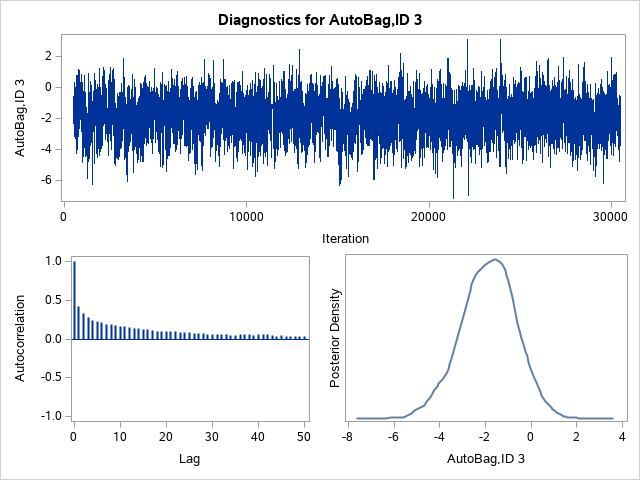
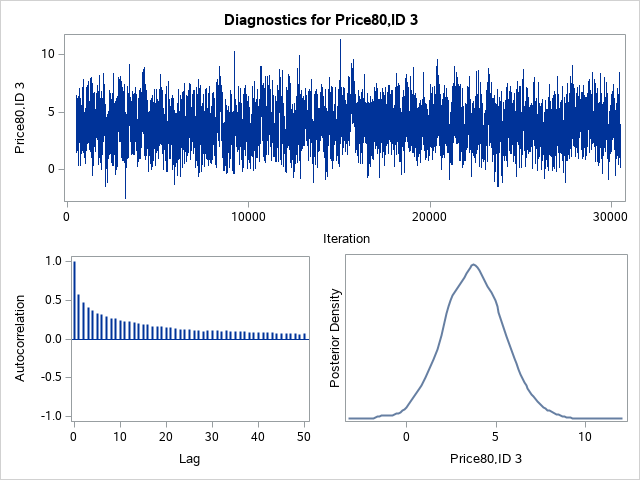
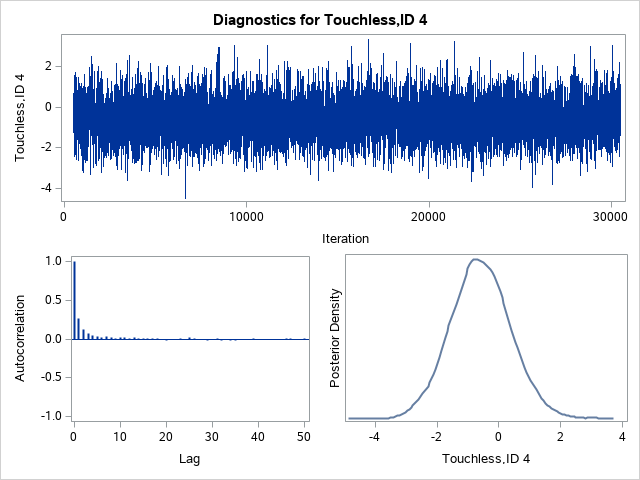
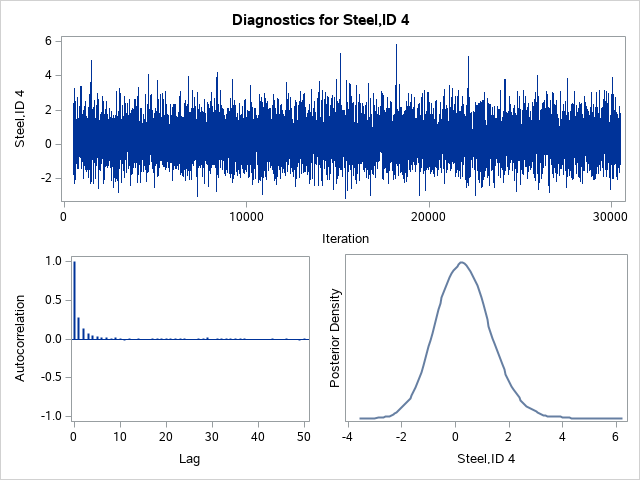
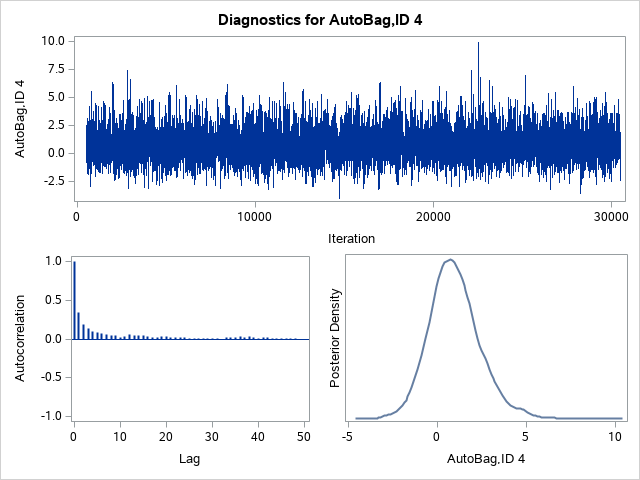
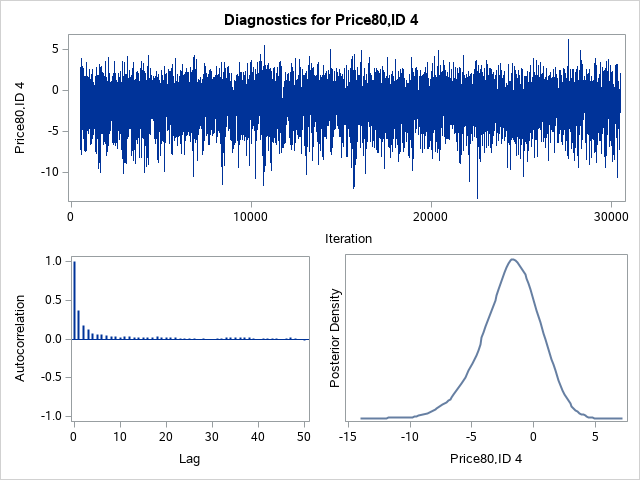
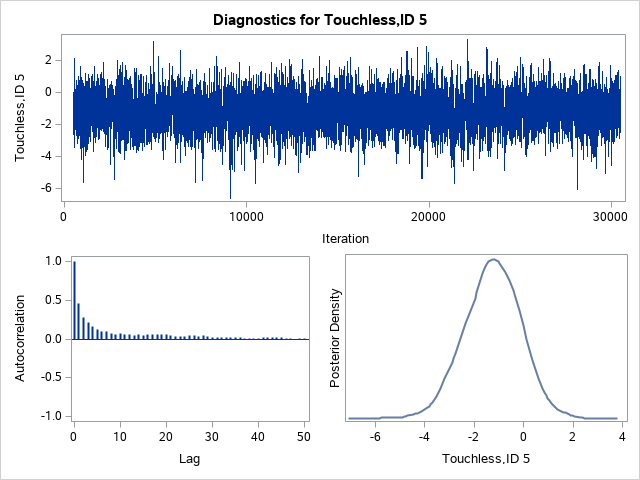
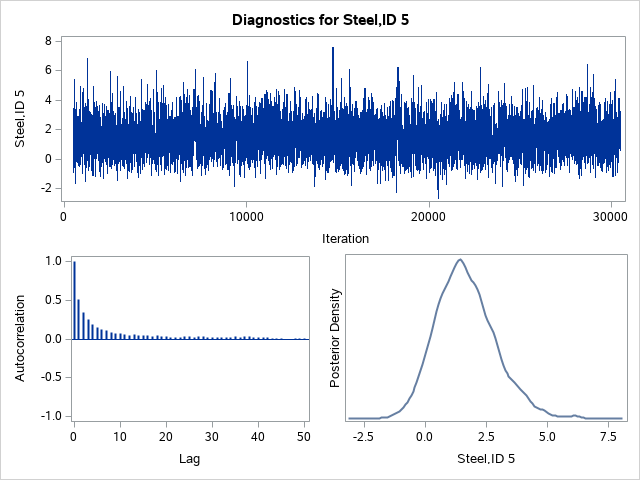
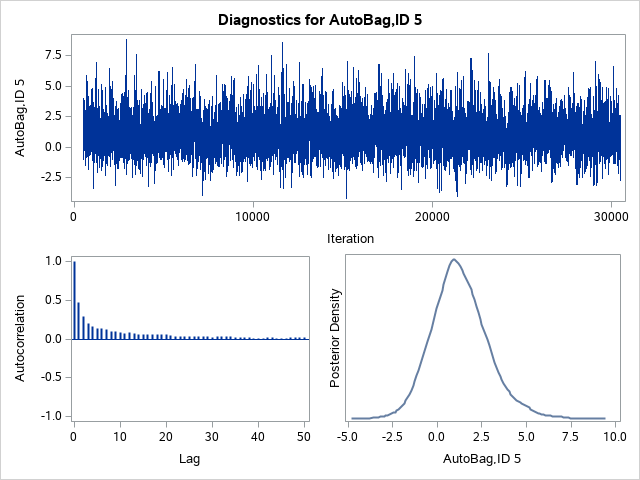
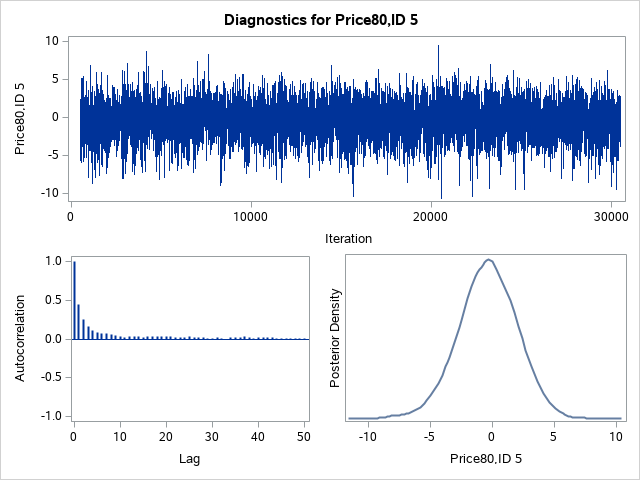

In [8]:
proc bchoice data=Trashcan seed=1 nmc=30000 thin=2 nthreads=4;
   class ID Task;
   model Choice = Touchless Steel AutoBag Price80 / choiceset=(ID Task);
   random Touchless Steel AutoBag Price80 / sub=ID monitor=(1 to 5) type=un;
run;

